# Datafest 2026, reto preliminar: auditoría del techo del Gini

**Por qué el Gini legítimo no supera 0,26 y qué se probó para mejorarlo.**

El modelo campeón del notebook solucion_preliminar_2026.ipynb obtuvo un Gini de 0,260 en prueba y 0,249 en la muestra fuera de tiempo. Este notebook audita ese resultado con una pregunta concreta: ¿el techo se debe a una falla del pipeline o a la información que contienen los datos?

Para responderla se hace ingeniería inversa del generador de datos, una auditoría de cada variable, una medición del ruido estadístico del Gini, una ablación controlada de fuga de datos y más de setenta experimentos de mejora. Todos los experimentos se evalúan con el mismo protocolo temporal.

Estructura del notebook:

1. Configuración del entorno.
2. Estructura del panel.
3. Auditoría de variables: ventana temporal, definición y fuente.
4. Ingeniería inversa del generador.
5. Agotamiento de la población.
6. Protocolo de validación.
7. Ruido de medición y techo teórico.
8. Ablación de fuga de datos.
9. Experimentos de mejora.
10. Plan de mejora dirigido: variables, modelos, búsqueda, monotonía y mezcla por rangos.
11. Lectura por segmentos para el negocio.
12. Entrenamiento final y archivos de envío.
13. Conclusiones.

Convención de signos: el Gini se calcula como dos veces el AUC menos uno, de modo que solo importa el orden de los clientes.

## 1. Configuración del entorno

Se usa el entorno conda datafest. Todas las funciones se definen dentro del notebook. Las figuras se guardan en SVG y PDF en la carpeta figuras/auditoria, y las tablas en artefactos/auditoria.

La paleta categórica es la validada para daltonismo del notebook principal (azul, naranja y aqua en ese orden fijo). Las figuras usan un solo eje vertical, marcas delgadas y cuadrícula tenue.

In [1]:
import os, json, time, warnings, itertools, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata
import statsmodels.api as sm
import statsmodels.formula.api as smf
import sklearn, lightgbm as lgb, xgboost as xgb, catboost as cb, optuna
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, brier_score_loss, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, KBinsDiscretizer, SplineTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

SEMILLA = 42
RAIZ = Path.cwd().parent
DATOS = RAIZ.parent / '2026_Datafest Coding Test-20260929T230039Z-1-001' / 'Datafest Coding Test'
FIG, ART, ENT = RAIZ / 'figuras' / 'auditoria', RAIZ / 'artefactos' / 'auditoria', RAIZ / 'entrega'
for p in (FIG, ART, ENT):
    p.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4'
GRIS, TINTA, TINTA2 = '#8a8984', '#0b0b0b', '#52514e'
mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.bbox': 'tight', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelcolor': TINTA2, 'axes.edgecolor': '#c9c8c2', 'xtick.color': TINTA2,
    'ytick.color': TINTA2, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'lines.linewidth': 2,
    'legend.frameon': False, 'svg.fonttype': 'none', 'pdf.fonttype': 42})

def guardar(fig, nombre):
    for ext in ('svg', 'pdf'):
        fig.savefig(FIG / f'{nombre}.{ext}')
    plt.show()

print('python', platform.python_version(), '| sklearn', sklearn.__version__, '| lightgbm', lgb.__version__,
      '| xgboost', xgb.__version__, '| catboost', cb.__version__, '| optuna', optuna.__version__)

python 3.11.16 | sklearn 1.9.0 | lightgbm 4.7.0 | xgboost 3.2.0 | catboost 1.2.10 | optuna 4.9.0


/home/germain/radioconda/envs/datafest/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
CAT = ['ocupacion', 'region', 'canal_adquisicion', 'banda_riesgo', 'dispositivo_principal']
BOOL = ['tiene_tarjeta_credito', 'activo_movil', 'es_nuevo_cliente', 'tiene_prestamo', 'tiene_seguro']
NUM = ['edad', 'ingresos', 'ratio_deuda_ingresos', 'antiguedad_cuenta_meses', 'numero_productos', 'saldo_promedio',
       'dias_ultima_transaccion', 'antiguedad_direccion_meses', 'visitas_web_ultimos_90_dias', 'distancia_sucursal_km',
       'dia_preferido_pago']
BASE = NUM + CAT + BOOL

tr = pd.read_csv(DATOS / 'train.csv')
te = pd.read_csv(DATOS / 'test.csv')
te['objetivo'] = np.nan
al = pd.concat([tr, te], ignore_index=True)
al['t'] = (al.mes // 100 - 2026) * 12 + al.mes % 100
al = al.sort_values(['id_cliente', 't']).reset_index(drop=True)
for c in BOOL:
    al[c] = al[c].astype(int)
for c in CAT:
    al[c] = pd.Categorical(al[c], categories=sorted(tr[c].unique()))
g = al.groupby('id_cliente')
al['h_k'] = g.cumcount()
al['h_first'] = g.t.transform('min')
al['h_jan'] = (al.h_first == 1).astype(int)
al['h_new'] = (al.h_k == 0).astype(int)
lab = al[al.objetivo.notna()].copy()
print('train', tr.shape, '| test', te.shape, '| clientes', al.id_cliente.nunique())

train (110100, 25) | test (9900, 25) | clientes 26467


## 2. Estructura del panel

Antes de modelar hay que entender cómo se construyó el panel: quién entra, quién sale y qué cambia de un mes a otro.

In [3]:
mensual = lab.groupby('t').agg(filas=('objetivo', 'size'), tasa=('objetivo', 'mean'))
mensual['ee'] = np.sqrt(mensual.tasa * (1 - mensual.tasa) / mensual.filas)
entradas = al[al.h_k == 0].groupby('t').size().rename('nuevos_en_panel')
ult = al[al.t == g.t.transform('max')]
salida = ult[ult.t < 12].objetivo.agg(['size', 'mean']).rename({'size': 'clientes_que_salen', 'mean': 'proporcion_que_convirtio'})
huecos = ((g.t.transform('max') - g.t.transform('min') + 1) != g.t.transform('size')).mean()
print(salida.to_string(), f'\nclientes con meses faltantes en su historial: {huecos:.3f}')
nr = lab.assign(grupo=np.where(lab.h_k == 0, 'nuevo en el panel', 'recurrente')).groupby(['t', 'grupo']).objetivo.mean().unstack()
pd.concat([mensual, entradas, nr], axis=1).round(4)

clientes_que_salen          16567.0
proporcion_que_convirtio        1.0 
clientes con meses faltantes en su historial: 0.000


,filas,tasa,ee,nuevos_en_panel,nuevo en el panel,recurrente
t,,,,,,
1,10400.0,0.1462,0.0035,10400,0.1462,NaN
2,9800.0,0.1574,0.0037,921,0.1705,0.1561
3,10300.0,0.1483,0.0035,2043,0.1596,0.1455
4,9600.0,0.1534,0.0037,827,0.1415,0.1546
5,10100.0,0.1568,0.0036,1973,0.1673,0.1543
6,10350.0,0.1546,0.0036,1834,0.1685,0.1516
7,9700.0,0.1454,0.0036,950,0.1705,0.1426
8,10050.0,0.1442,0.0035,1760,0.1756,0.1375
9,9900.0,0.1407,0.0035,1299,0.1678,0.1366


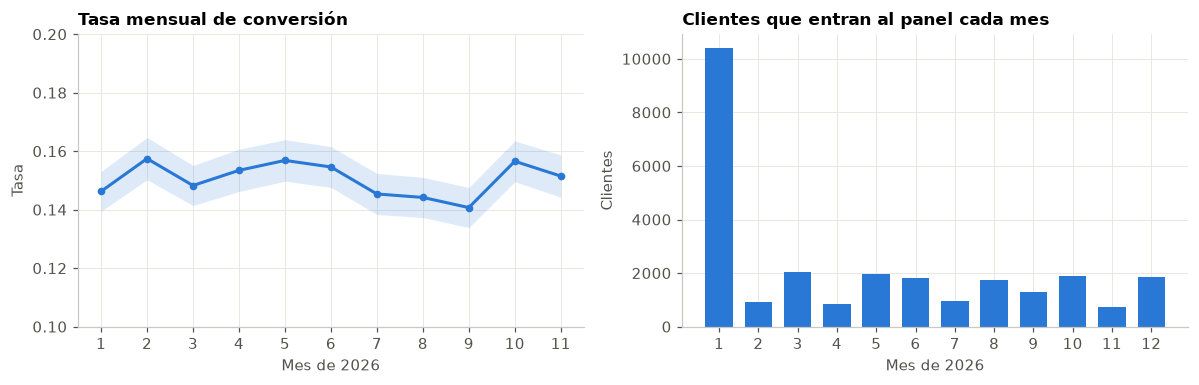

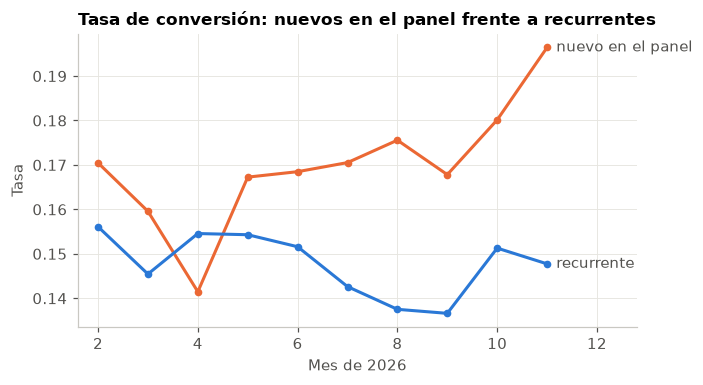

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
x = mensual.index
ax[0].fill_between(x, mensual.tasa - 1.96 * mensual.ee, mensual.tasa + 1.96 * mensual.ee, color=AZUL, alpha=0.15, lw=0)
ax[0].plot(x, mensual.tasa, color=AZUL, marker='o', ms=4)
ax[0].set(title='Tasa mensual de conversión', xlabel='Mes de 2026', ylabel='Tasa', ylim=(0.10, 0.20), xticks=range(1, 12))
ax[1].bar(entradas.index, entradas.values, color=AZUL, width=0.7)
ax[1].set(title='Clientes que entran al panel cada mes', xlabel='Mes de 2026', ylabel='Clientes', xticks=range(1, 13))
fig.tight_layout(); guardar(fig, 'A01_panel_tasa_y_entradas')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for col, color in [('nuevo en el panel', NARANJA), ('recurrente', AZUL)]:
    ax.plot(nr.index[1:], nr[col].iloc[1:], color=color, marker='o', ms=4)
    ax.annotate(col, (nr.index[-1], nr[col].iloc[-1]), xytext=(6, 0), textcoords='offset points', color=TINTA2, va='center')
ax.set(title='Tasa de conversión: nuevos en el panel frente a recurrentes', xlabel='Mes de 2026', ylabel='Tasa', xlim=(1.6, 12.8))
fig.tight_layout(); guardar(fig, 'A02_tasa_nuevos_recurrentes')

**Lectura de las figuras A01 y A02.** La tasa mensual oscila entre 14,1 y 15,7 por ciento, sin tendencia ni estacionalidad: todos los meses caen dentro del intervalo de confianza de los demás. Ningún cliente sale del panel sin convertir: los 16 567 clientes que dejan de aparecer antes de diciembre lo hacen en el mes de su conversión, y ninguno tiene meses faltantes. Cada mes entran entre 728 y 2043 clientes. Desde mayo, los clientes que recién entran al panel convierten más que los recurrentes (entre 16,7 y 19,6 por ciento frente a 13,7 y 15,4 por ciento), y la brecha crece hacia fin de año. Es la primera señal de que la población se agota.

## 3. Auditoría de variables: ventana temporal, definición y fuente

El reto no entrega marcas de tiempo, fuente ni definición formal de las variables más allá de metaData.csv. La auditoría es empírica: compara cómo debería comportarse cada variable si se midiera mes a mes con cómo se comporta en realidad. Por ejemplo, la antigüedad de la cuenta debería subir un mes cada mes, y los días desde la última transacción deberían subir cerca de 30 o reiniciarse.

In [5]:
esperado = {'dias_ultima_transaccion': 'subir cerca de 30 o reiniciarse', 'antiguedad_cuenta_meses': 'subir 1 por mes',
            'antiguedad_direccion_meses': 'subir 1 por mes', 'edad': 'subir 1 cada 12 meses',
            'numero_productos': 'cambiar al contratar o cancelar', 'banda_riesgo': 'cambiar con la evaluación de riesgo',
            'activo_movil': 'cambiar con el uso de la app', 'dias_ultima_interaccion': 'subir cerca de 30 o reiniciarse'}
cols = [c for c in BASE + ['dias_ultima_interaccion']]
cambio = (al.groupby('id_cliente')[cols].nunique() > 1).mean().sort_values()
foto = pd.DataFrame({'clientes_con_cambio': cambio, 'esperado_si_fuera_mensual': [esperado.get(c, '') for c in cambio.index]})
foto.to_csv(ART / 'A03_variables_foto_fija.csv')
foto.round(3)

,clientes_con_cambio,esperado_si_fuera_mensual
edad,0.000,subir 1 cada 12 meses
ingresos,0.000,
ratio_deuda_ingresos,0.000,
antiguedad_cuenta_meses,0.000,subir 1 por mes
numero_productos,0.000,cambiar al contratar o cancelar
saldo_promedio,0.000,
dias_ultima_transaccion,0.000,subir cerca de 30 o reiniciarse
antiguedad_direccion_meses,0.000,subir 1 por mes
visitas_web_ultimos_90_dias,0.000,
distancia_sucursal_km,0.000,


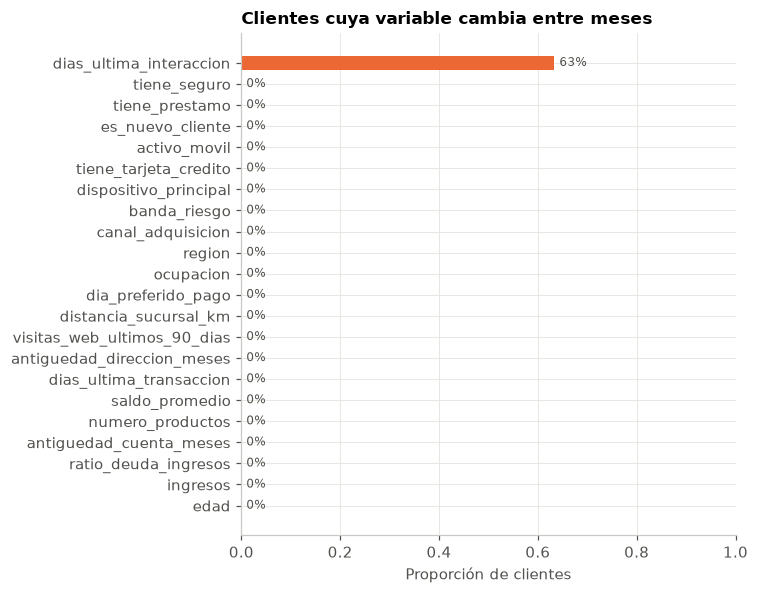

In [6]:
fig, ax = plt.subplots(figsize=(7, 5.5))
colores = [NARANJA if v > 0 else AZUL for v in foto.clientes_con_cambio]
ax.barh(foto.index, foto.clientes_con_cambio, color=colores, height=0.65)
for i, v in enumerate(foto.clientes_con_cambio):
    ax.text(v + 0.01, i, f'{v:.0%}', va='center', color=TINTA2, fontsize=8)
ax.set(title='Clientes cuya variable cambia entre meses', xlabel='Proporción de clientes', xlim=(0, 1))
fig.tight_layout(); guardar(fig, 'A03_variables_foto_fija')

In [7]:
cl = al.drop_duplicates('id_cliente')
ent = al[al.h_k == 0].groupby('t').agg(antiguedad_media=('antiguedad_cuenta_meses', 'mean'),
                                        recencia_media=('dias_ultima_transaccion', 'mean'), es_nuevo=('es_nuevo_cliente', 'mean'))
print('Clientes que entran al panel cada mes: la foto no tiene fecha identificable')
display(ent.round(2).T)
print('Antigüedad de cuenta según es_nuevo_cliente')
display(cl.groupby('es_nuevo_cliente').antiguedad_cuenta_meses.describe().round(1))
print('Variables financieras por banda de riesgo')
display(cl.groupby('banda_riesgo', observed=True)[['ratio_deuda_ingresos', 'ingresos', 'saldo_promedio', 'tiene_prestamo', 'edad']].mean().round(3))

Clientes que entran al panel cada mes: la foto no tiene fecha identificable


t,1,2,3,4,5,6,7,8,9,10,11,12
antiguedad_media,89.33,90.88,90.44,90.75,87.39,88.18,91.04,92.89,89.11,88.51,91.10,92.38
recencia_media,184.04,188.23,182.31,183.15,185.06,179.54,180.34,179.18,183.09,177.38,183.74,183.06
es_nuevo,0.19,0.19,0.19,0.18,0.20,0.20,0.18,0.20,0.19,0.18,0.18,0.19


Antigüedad de cuenta según es_nuevo_cliente


,count,mean,std,min,25%,50%,75%,max
es_nuevo_cliente,,,,,,,,
0,21423.0,90.0,51.6,1.0,45.0,90.0,135.0,179.0
1,5044.0,88.9,51.5,1.0,43.0,88.0,133.0,179.0


Variables financieras por banda de riesgo


,ratio_deuda_ingresos,ingresos,saldo_promedio,tiene_prestamo,edad
banda_riesgo,,,,,
high,0.329,66124.353,26517.169,0.443,46.795
low,0.329,65275.045,26415.439,0.446,46.366
medium,0.325,65256.269,26572.133,0.439,46.645


**Lectura de la figura A03 y de las tablas.** Las 21 variables de la ficha son idénticas en todos los meses de cada cliente, incluso las que por definición deberían cambiar, como la antigüedad de la cuenta o los días desde la última transacción. No son mediciones mensuales sino una foto tomada una sola vez. La foto tampoco tiene fecha identificable: quienes entran al panel en noviembre tienen la misma antigüedad media (entre 87 y 93 meses) y la misma recencia media (cerca de 183 días) que quienes entran en enero.

Hay además dos definiciones inconsistentes. es_nuevo_cliente no identifica clientes nuevos: su antigüedad mediana es de 88 meses, frente a 90 en el resto. banda_riesgo, la variable más predictiva, no se relaciona con la deuda: el ratio medio es 0,329, 0,329 y 0,325 en las bandas alta, baja y media, y los ingresos son iguales. Su fuente es independiente del resto de la ficha.

Consecuencia: no existe una ventana temporal que resumir, de modo que las variables de tendencia, velocidad o ventanas de 3, 6 y 9 meses no pueden aportar sobre la ficha.

In [8]:
al['igual_transaccion'] = al.dias_ultima_interaccion == al.dias_ultima_transaccion
al['igual_previo'] = al.groupby('id_cliente').igual_transaccion.shift()
mec = pd.DataFrame({m: {'proporcion_igual': s.igual_transaccion.mean(), 'teorico_1_menos_(m_1)/11': 1 - (m - 1) / 11,
                        'igual_si_antes_igual': s[s.igual_previo == True].igual_transaccion.mean(),
                        'igual_si_antes_distinto': s[s.igual_previo == False].igual_transaccion.mean()}
                    for m, s in al.groupby('t')})
dif = al[~al.igual_transaccion]
sw = al[(al.igual_previo == True) & al.objetivo.notna()].assign(resorteo=lambda d: (~d.igual_transaccion).astype(int))
print(f'correlación del valor sorteado con la transacción: {np.corrcoef(dif.dias_ultima_interaccion, dif.dias_ultima_transaccion)[0, 1]:.4f}')
print('tasa de conversión el mes del sorteo frente al resto:', sw.groupby('resorteo').objetivo.mean().round(4).to_dict())
mec.to_csv(ART / 'A04_mecanismo_dias_ultima_interaccion.csv')
mec.round(3)

correlación del valor sorteado con la transacción: 0.0013
tasa de conversión el mes del sorteo frente al resto: {0: 0.1506, 1: 0.1463}


,1,2,3,4,5,6,7,8,9,10,11,12
proporcion_igual,1.0,0.909,0.819,0.728,0.637,0.547,0.457,0.365,0.276,0.184,0.094,0.003
teorico_1_menos_(m_1)/11,1.0,0.909,0.818,0.727,0.636,0.545,0.455,0.364,0.273,0.182,0.091,0.000
igual_si_antes_igual,NaN,0.911,0.823,0.727,0.631,0.551,0.451,0.360,0.268,0.181,0.096,0.004
igual_si_antes_distinto,NaN,NaN,0.832,0.735,0.643,0.534,0.464,0.375,0.281,0.185,0.094,0.003


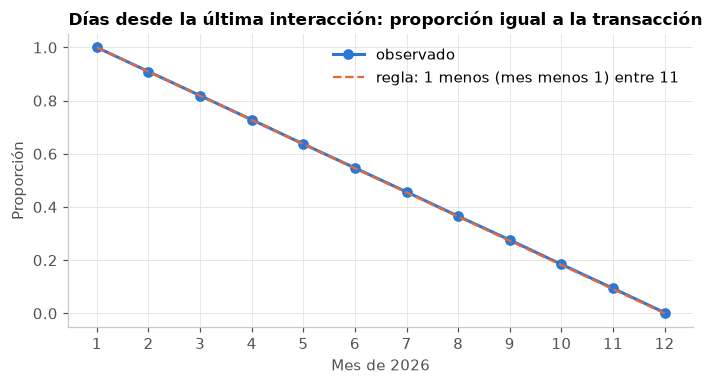

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(mec.columns, mec.loc['proporcion_igual'], color=AZUL, marker='o', ms=6, label='observado')
ax.plot(mec.columns, mec.loc['teorico_1_menos_(m_1)/11'], color=NARANJA, lw=1.5, ls='--', label='regla: 1 menos (mes menos 1) entre 11')
ax.legend(loc='upper right')
ax.set(title='Días desde la última interacción: proporción igual a la transacción', xlabel='Mes de 2026', ylabel='Proporción', xticks=range(1, 13))
fig.tight_layout(); guardar(fig, 'A04_mecanismo_dias_ultima_interaccion')

**Lectura de la figura A04.** La única variable que cambia sigue una regla exacta. Cada mes, y de forma independiente del mes anterior, dias_ultima_interaccion copia a dias_ultima_transaccion con probabilidad 1 menos (mes menos 1) entre 11; en otro caso toma un valor al azar entre 1 y 364. La proporción observada coincide con la regla en todos los meses (100 por ciento en enero y 0,3 por ciento en diciembre), y la probabilidad de coincidir es la misma si el mes anterior coincidía o no. El valor sorteado no se correlaciona con la transacción (0,001) ni anticipa la conversión (14,6 frente a 15,1 por ciento). Es una trampa de deriva programada: en enero la variable es una copia de la recencia y en diciembre es ruido puro. Se excluye.

## 4. Ingeniería inversa del generador

Se busca qué variables tienen efecto real, con qué forma y con qué interacciones. Para no contaminar la confirmación, este análisis usa solo enero a agosto.

**Prueba de razón de verosimilitud por variable.** Se ajusta una regresión logística con todas las variables (splines de cuatro grados de libertad para las numéricas) y se retira una variable por vez. Si al retirarla la verosimilitud no cae de forma significativa, la variable no aporta. Como un mismo cliente aparece en varios meses, los valores p son optimistas: una variable no significativa aquí es, con más razón, ruido.

In [10]:
d8 = lab[lab.t <= 8].copy()
for c in CAT:
    d8[c] = d8[c].astype(str)
d8['y'] = d8.objetivo
def termino(c):
    return f'C({c})' if c in CAT else (c if c in BOOL else f'bs({c}, df=4)')
glm = lambda f: smf.glm('y ~ ' + f, d8, family=sm.families.Binomial()).fit()
completo = glm(' + '.join(termino(c) for c in BASE))
filas = []
for c in BASE:
    m = glm(' + '.join(termino(x) for x in BASE if x != c))
    lr = 2 * (completo.llf - m.llf); gl = m.df_resid - completo.df_resid
    filas.append((c, lr, gl, stats.chi2.sf(lr, gl)))
rv = pd.DataFrame(filas, columns=['variable', 'razon_verosimilitud', 'gl', 'p']).sort_values('razon_verosimilitud', ascending=False).set_index('variable')
rv['tiene_efecto'] = rv.p < 0.01
REALES = rv.index[rv.tiene_efecto].tolist()
rv.to_csv(ART / 'A05_razon_verosimilitud.csv')
print('Variables con efecto real:', REALES)
rv.round(4)

Variables con efecto real: ['banda_riesgo', 'numero_productos', 'dias_ultima_transaccion', 'activo_movil', 'tiene_tarjeta_credito', 'ratio_deuda_ingresos']


,razon_verosimilitud,gl,p,tiene_efecto
variable,,,,
banda_riesgo,1105.0621,2,0.0000,True
numero_productos,619.1585,4,0.0000,True
dias_ultima_transaccion,226.8950,4,0.0000,True
activo_movil,104.5416,1,0.0000,True
tiene_tarjeta_credito,48.3401,1,0.0000,True
ratio_deuda_ingresos,21.0018,4,0.0003,True
canal_adquisicion,9.1502,4,0.0575,False
antiguedad_cuenta_meses,8.9746,4,0.0617,False
distancia_sucursal_km,7.5434,4,0.1098,False


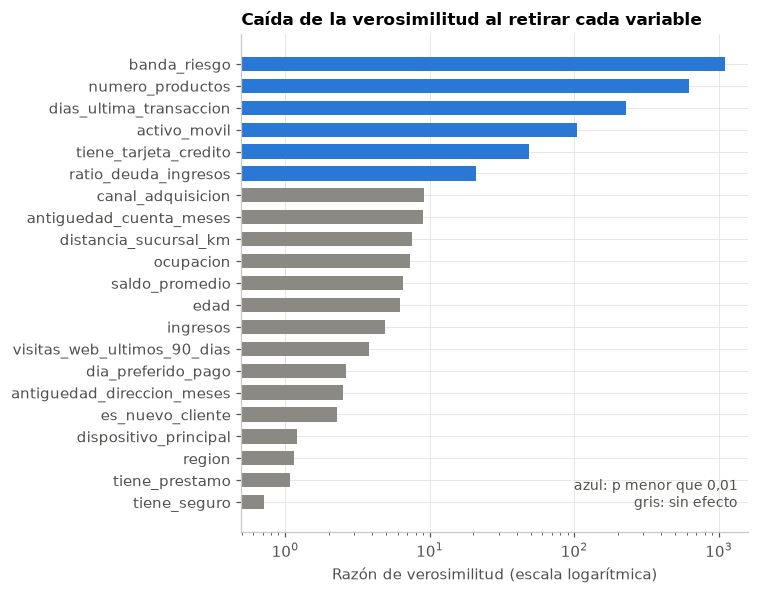

In [11]:
fig, ax = plt.subplots(figsize=(7, 5.5))
r_ = rv.iloc[::-1]
ax.barh(r_.index, r_.razon_verosimilitud, color=[AZUL if t else GRIS for t in r_.tiene_efecto], height=0.65)
ax.set_xscale('log')
ax.set(title='Caída de la verosimilitud al retirar cada variable', xlabel='Razón de verosimilitud (escala logarítmica)')
ax.text(0.98, 0.05, 'azul: p menor que 0,01\ngris: sin efecto', transform=ax.transAxes, ha='right', color=TINTA2, fontsize=9)
fig.tight_layout(); guardar(fig, 'A05_razon_verosimilitud')

**Lectura de la figura A05.** Solo seis variables tienen efecto: banda_riesgo, numero_productos, dias_ultima_transaccion, activo_movil, tiene_tarjeta_credito y ratio_deuda_ingresos. Las otras quince no alcanzan significancia, incluso con valores p optimistas; canal_adquisicion y antiguedad_cuenta_meses quedan al borde, con p cercano a 0,06. El efecto de numero_productos no es lineal (p menor que 0,001) y el de ratio_deuda_ingresos se aparta poco de la linealidad (p de 0,015).

**Forma e interacciones.** Se prueba si cada efecto numérico es lineal y qué pares de variables reales interactúan.

In [12]:
no_lineal = []
for c in NUM:
    m = glm(' + '.join((c if x == c else termino(x)) for x in BASE))
    lr = 2 * (completo.llf - m.llf); no_lineal.append((c, lr, stats.chi2.sf(lr, 3)))
display(pd.DataFrame(no_lineal, columns=['variable', 'razon_verosimilitud', 'p_no_lineal']).set_index('variable').round(4))

T6 = {'banda_riesgo': 'C(banda_riesgo)', 'numero_productos': 'C(numero_productos)', 'dias_ultima_transaccion': 'bs(dias_ultima_transaccion, df=4)',
      'activo_movil': 'activo_movil', 'tiene_tarjeta_credito': 'tiene_tarjeta_credito', 'ratio_deuda_ingresos': 'bs(ratio_deuda_ingresos, df=3)'}
L6 = {'banda_riesgo': 'C(banda_riesgo)', 'numero_productos': 'C(numero_productos)', 'dias_ultima_transaccion': 'dias_ultima_transaccion',
      'activo_movil': 'activo_movil', 'tiene_tarjeta_credito': 'tiene_tarjeta_credito', 'ratio_deuda_ingresos': 'ratio_deuda_ingresos'}
aditivo = glm(' + '.join(T6.values()))
pares = []
for a, b in itertools.combinations(T6, 2):
    m = glm(' + '.join(T6.values()) + f' + {L6[a]}:{L6[b]}')
    lr = 2 * (m.llf - aditivo.llf); gl = aditivo.df_resid - m.df_resid
    pares.append((a, b, lr, gl, stats.chi2.sf(lr, max(gl, 1))))
inter = pd.DataFrame(pares, columns=['a', 'b', 'razon_verosimilitud', 'gl', 'p']).sort_values('razon_verosimilitud', ascending=False)
inter.to_csv(ART / 'A06_interacciones.csv', index=False)
inter.round(4)

,razon_verosimilitud,p_no_lineal
variable,,
edad,1.3949,0.7067
ingresos,0.5798,0.9010
ratio_deuda_ingresos,10.4803,0.0149
antiguedad_cuenta_meses,2.0704,0.5579
numero_productos,54.4112,0.0000
saldo_promedio,1.8557,0.6029
dias_ultima_transaccion,5.1758,0.1594
antiguedad_direccion_meses,2.2646,0.5193
visitas_web_ultimos_90_dias,3.3000,0.3476


,a,b,razon_verosimilitud,gl,p
0,banda_riesgo,numero_productos,343.6711,8,0.0000
1,banda_riesgo,dias_ultima_transaccion,231.2297,2,0.0000
2,banda_riesgo,activo_movil,52.6844,2,0.0000
12,activo_movil,tiene_tarjeta_credito,45.2296,1,0.0000
6,numero_productos,activo_movil,36.6416,4,0.0000
7,numero_productos,tiene_tarjeta_credito,33.1177,4,0.0000
3,banda_riesgo,tiene_tarjeta_credito,29.6582,2,0.0000
13,activo_movil,ratio_deuda_ingresos,16.9430,1,0.0000
8,numero_productos,ratio_deuda_ingresos,8.9142,4,0.0633
5,numero_productos,dias_ultima_transaccion,5.7308,4,0.2202


In [13]:
d8['recencia'] = pd.cut(d8.dias_ultima_transaccion, [0, 30, 60, 90, 120, 150, 180, 240, 300, 365])
rec_banda = d8.groupby(['recencia', 'banda_riesgo'], observed=True).y.mean().unstack()
prod_banda = pd.crosstab(d8.banda_riesgo, d8.numero_productos, values=d8.y, aggfunc='mean')
def corte_optimo(s, col, malla):
    out = []
    for c in malla:
        a, b = s[s[col] <= c].y, s[s[col] > c].y
        if min(len(a), len(b)) < 200: continue
        ll = sum(len(x) * (x.mean() * np.log(x.mean()) + (1 - x.mean()) * np.log(1 - x.mean())) for x in (a, b))
        out.append((c, ll, a.mean(), b.mean()))
    return pd.DataFrame(out, columns=['corte', 'logverosimilitud', 'tasa_hasta', 'tasa_despues']).sort_values('logverosimilitud', ascending=False).head(1)
cortes = pd.concat([
    corte_optimo(d8[d8.banda_riesgo == 'high'], 'dias_ultima_transaccion', range(150, 211, 2)).assign(regla='riesgo alto, días desde la última transacción'),
    corte_optimo(d8[d8.banda_riesgo == 'low'], 'numero_productos', [1, 2, 3, 4]).assign(regla='riesgo bajo, número de productos'),
    corte_optimo(d8[d8.activo_movil == 0], 'ratio_deuda_ingresos', np.round(np.arange(0.35, 0.65, 0.01), 2)).assign(regla='sin app móvil, ratio de deuda')]).set_index('regla')
lo = d8[d8.banda_riesgo == 'low']
celdas_bajo = lo.groupby([(lo.numero_productos >= 3).rename('tres_o_mas_productos'), (lo.activo_movil * lo.tiene_tarjeta_credito).rename('movil_y_tarjeta'),
                          (lo.dias_ultima_transaccion <= 90).rename('recencia_hasta_90')]).y.agg(['size', 'mean'])
cortes.to_csv(ART / 'A07_cortes_optimos.csv'); display(cortes.round(4)); celdas_bajo.round(3)

,corte,logverosimilitud,tasa_hasta,tasa_despues
regla,,,,
"riesgo alto, días desde la última transacción",182.00,-4478.2884,0.1370,0.0456
"riesgo bajo, número de productos",2.00,-18101.7662,0.1553,0.2943
"sin app móvil, ratio de deuda",0.55,-10810.7697,0.1400,0.0954


size   mean
tres_o_mas_productos movil_y_tarjeta recencia_hasta_90              
False                0               False              11719  0.128
                                     True                3641  0.146
                     1               False              10942  0.173
                                     True                3329  0.205
True                 0               False               3852  0.227
                                     True                1169  0.265
                     1               False               2830  0.360
                                     True                 910  0.411

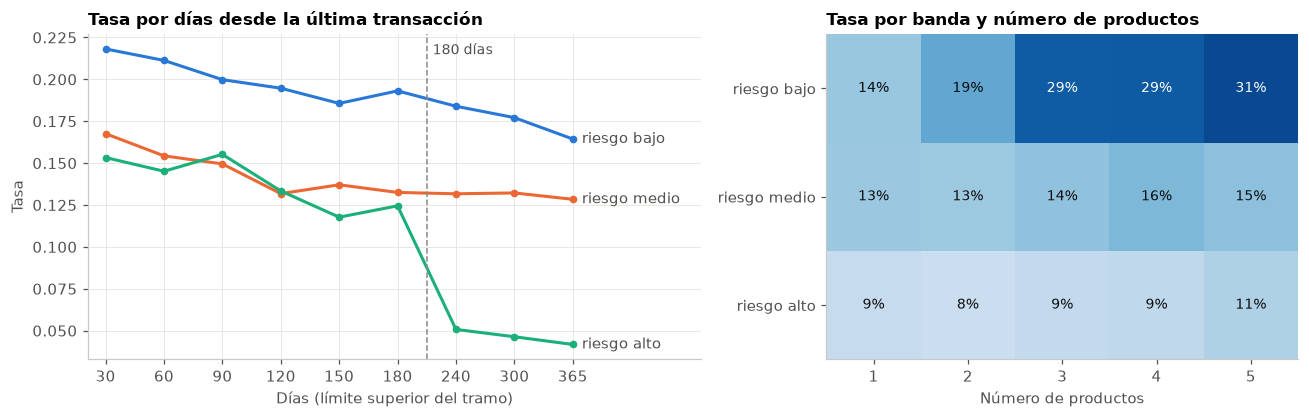

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw={'width_ratios': [1.3, 1]})
etiquetas = {'low': 'riesgo bajo', 'medium': 'riesgo medio', 'high': 'riesgo alto'}
xs = np.arange(len(rec_banda))
for b, color in [('low', AZUL), ('medium', NARANJA), ('high', AQUA)]:
    ax[0].plot(xs, rec_banda[b], color=color, marker='o', ms=4)
    ax[0].annotate(etiquetas[b], (xs[-1], rec_banda[b].iloc[-1]), xytext=(6, 0), textcoords='offset points', color=TINTA2, va='center')
ax[0].axvline(5.5, color=GRIS, lw=1, ls='--'); ax[0].text(5.6, 0.215, '180 días', color=TINTA2, fontsize=9)
ax[0].set_xticks(xs, [str(i.right) for i in rec_banda.index]); ax[0].set_xlim(-0.3, len(xs) + 1.2)
ax[0].set(title='Tasa por días desde la última transacción', xlabel='Días (límite superior del tramo)', ylabel='Tasa')
im = ax[1].imshow(prod_banda.loc[['low', 'medium', 'high']].values, cmap='Blues', vmin=0, vmax=0.35, aspect='auto')
for i in range(3):
    for j in range(5):
        v = prod_banda.loc[['low', 'medium', 'high']].values[i, j]
        ax[1].text(j, i, f'{v:.0%}', ha='center', va='center', color='white' if v > 0.22 else TINTA, fontsize=9)
ax[1].set_xticks(range(5), range(1, 6)); ax[1].set_yticks(range(3), ['riesgo bajo', 'riesgo medio', 'riesgo alto']); ax[1].grid(False)
ax[1].set(title='Tasa por banda y número de productos', xlabel='Número de productos')
fig.tight_layout(); guardar(fig, 'A06_reglas_del_generador')

**Lectura de la figura A06 y de las tablas.** El generador funciona como un sistema de reglas por segmento con interacciones de hasta tres variables:

* Riesgo alto: la tasa cae en escalón de 13,7 a 4,6 por ciento cuando pasan más de 182 días desde la última transacción.
* Riesgo bajo: tener 3 o más productos sube la tasa de 15,5 a 29,4 por ciento; combinado con app móvil, tarjeta y una recencia de hasta 90 días, llega a 41 por ciento.
* Sin app móvil: un ratio de deuda mayor que 0,55 baja la tasa de 14,0 a 9,5 por ciento.
* Riesgo medio: la tasa es casi plana, entre 13 y 16 por ciento, en todos los cortes.

Estas interacciones de orden tres explican por qué los árboles de profundidad 3 funcionan y los modelos aditivos no.

## 5. Agotamiento de la población

El poder predictivo de numero_productos cae con los meses. Hay dos explicaciones posibles. Si la foto envejece, la tasa de un mismo segmento cambiaría con la permanencia en el panel. Si la población se agota, la tasa de cada segmento se mantiene y lo que cambia es la composición, porque los clientes propensos convierten y salen. Se usan solo las cohortes que entraron después de enero, cuya permanencia se conoce.

In [15]:
nj = lab[lab.h_jan == 0].assign(
    permanencia=lambda d: np.minimum(d.h_k, 5),
    segmento=lambda d: np.where((d.banda_riesgo == 'low') & (d.numero_productos >= 3), 'riesgo bajo con 3 o más productos',
                                d.banda_riesgo.astype(str).map(etiquetas)))
tasa_seg = pd.crosstab(nj.segmento, nj.permanencia, values=nj.objetivo, aggfunc='mean')
composicion = (nj.segmento == 'riesgo bajo con 3 o más productos').groupby(nj.permanencia).mean()
m_ag = smf.glm('objetivo ~ C(segmento) * h_k', nj.assign(h_k=nj.h_k.astype(float)), family=sm.families.Binomial()).fit()
prueba = 2 * (m_ag.llf - smf.glm('objetivo ~ C(segmento)', nj, family=sm.families.Binomial()).fit().llf)
print(f'¿la permanencia cambia la tasa dentro del segmento? razón de verosimilitud {prueba:.2f} con 4 gl, p = {stats.chi2.sf(prueba, 4):.3f}')
gu = lambda s, c: 2 * roc_auc_score(s.objetivo, s[c]) - 1
poder = pd.Series({k: gu(s, 'numero_productos') for k, s in nj.groupby('permanencia')}, name='gini_numero_productos')
display(pd.concat([tasa_seg.T, composicion.rename('proporcion_alta_propension'), poder], axis=1).round(3))

¿la permanencia cambia la tasa dentro del segmento? razón de verosimilitud 7.86 con 4 gl, p = 0.097


,riesgo alto,riesgo bajo,riesgo bajo con 3 o más productos,riesgo medio,proporcion_alta_propension,gini_numero_productos
0,0.100,0.162,0.311,0.143,0.156,0.158
1,0.089,0.161,0.312,0.152,0.129,0.144
2,0.083,0.169,0.308,0.139,0.106,0.123
3,0.093,0.153,0.276,0.137,0.088,0.078
4,0.077,0.162,0.318,0.147,0.072,0.080
5,0.081,0.154,0.282,0.146,0.049,0.088


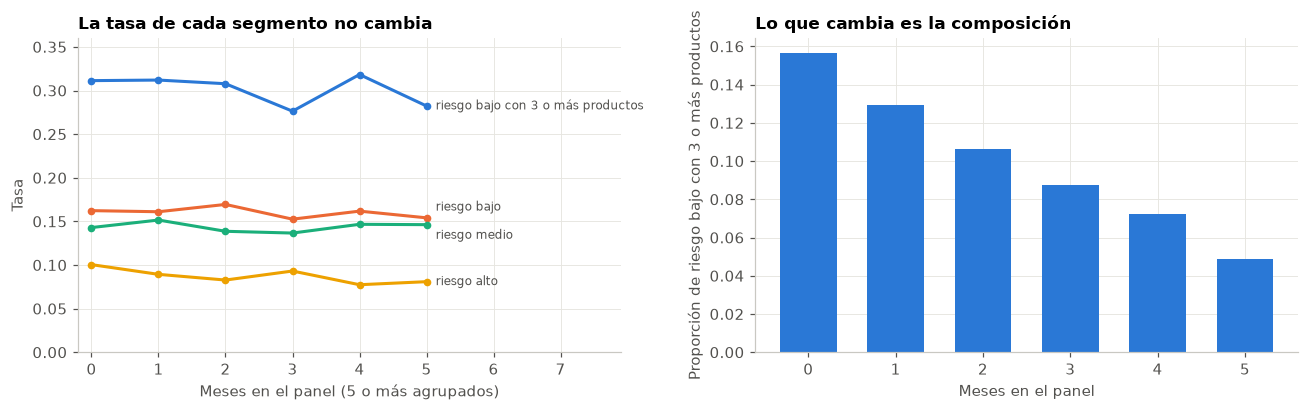

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for s_, color in [('riesgo bajo con 3 o más productos', AZUL), ('riesgo bajo', NARANJA), ('riesgo medio', AQUA), ('riesgo alto', AMARILLO)]:
    ax[0].plot(tasa_seg.columns, tasa_seg.loc[s_], color=color, marker='o', ms=4)
    dy = {'riesgo bajo': 7, 'riesgo medio': -7}.get(s_, 0)
    ax[0].annotate(s_, (5, tasa_seg.loc[s_, 5]), xytext=(6, dy), textcoords='offset points', color=TINTA2, va='center', fontsize=8)
ax[0].set(title='La tasa de cada segmento no cambia', xlabel='Meses en el panel (5 o más agrupados)', ylabel='Tasa', xlim=(-0.2, 7.9), ylim=(0, 0.36))
ax[1].bar(composicion.index, composicion.values, color=AZUL, width=0.65)
ax[1].set(title='Lo que cambia es la composición', xlabel='Meses en el panel', ylabel='Proporción de riesgo bajo con 3 o más productos')
fig.tight_layout(); guardar(fig, 'A07_agotamiento')

**Lectura de la figura A07.** Dentro de cada segmento, la tasa no cambia con la permanencia en el panel: riesgo bajo con 3 o más productos convierte 31 por ciento al entrar y entre 28 y 32 por ciento después (prueba de razón de verosimilitud con p de 0,10). Lo que cambia es la composición: los clientes de alta propensión pasan de 15,6 a 4,9 por ciento de la población porque convierten y salen. Por eso el Gini univariante de numero_productos cae de 0,158 a 0,088.

Implicaciones: la foto ya contiene todo lo que se puede saber del cliente; las variables de historial no pueden aportar información nueva; y diciembre, la población más agotada del año, es el mes más difícil de ordenar.

## 6. Protocolo de validación

**Esquema elegido: validación de ventana móvil mensual (walk forward).** Cada mes se predice con un modelo entrenado con todos los meses anteriores. Es la misma situación del envío: entrenar con enero a noviembre y predecir diciembre.

* Selección: marzo a agosto (seis cortes). Es el único tramo que se usa para elegir.
* Confirmación: septiembre a noviembre (tres cortes). Solo confirma; nunca se usa para elegir.
* Métrica principal: Gini medio mensual. También se reportan AUC, KS, PR AUC, F1 y Brier en confirmación. Para el F1 se elige en selección el porcentaje de clientes a contactar que maximiza el F1 y se aplica sin cambios en confirmación.
* Regla de decisión: una alternativa reemplaza al campeón solo si mejora la selección y la confirmación. La comparación se hace con un bootstrap pareado por cliente, porque las filas de un mismo cliente no son independientes.

Cada experimento se registra y el notebook avisa cuando supera al campeón o queda cerca.

In [17]:
SEL, CONF = list(range(3, 9)), [9, 10, 11]
MESES = SEL + CONF
OOF, RES = {}, []
gini = lambda y, p: 2 * roc_auc_score(y, p) - 1

def ks(y, p):
    f, t, _ = roc_curve(y, p); return float(np.max(t - f))

def wf(nombre, ajuste, variables, meses=MESES):
    # Validación de ventana móvil: cada mes se predice con un modelo entrenado con los meses anteriores.
    if nombre in OOF: return OOF[nombre]
    out = {}
    for m in meses:
        a, b = lab[lab.t < m], lab[lab.t == m]
        out[m] = (b.objetivo.values.astype(int), np.asarray(ajuste(a, b, variables), dtype=float), b.id_cliente.values)
    OOF[nombre] = out
    return out

def rango_mes(out, meses):
    return np.concatenate([rankdata(out[m][1]) / len(out[m][1]) for m in meses])

def top_por_mes(out, meses, q):
    return np.concatenate([out[m][1] >= np.quantile(out[m][1], 1 - q) for m in meses])

def resumen(nombre, out, grupo='', prob=True):
    gm = {m: gini(out[m][0], out[m][1]) for m in MESES}
    ys = np.concatenate([out[m][0] for m in SEL]); yc = np.concatenate([out[m][0] for m in CONF])
    malla = np.linspace(0.05, 0.6, 56)
    q = malla[int(np.argmax([f1_score(ys, top_por_mes(out, SEL, q)) for q in malla]))]
    rc = rango_mes(out, CONF); pc = np.concatenate([out[m][1] for m in CONF])
    return dict(grupo=grupo, modelo=nombre, gini_seleccion=np.mean([gm[m] for m in SEL]), gini_confirmacion=np.mean([gm[m] for m in CONF]),
                std_mensual=np.std(list(gm.values())), gini_minimo=min(gm.values()), auc_confirmacion=np.mean([(gm[m] + 1) / 2 for m in CONF]),
                ks_confirmacion=ks(yc, rc), pr_auc_confirmacion=average_precision_score(yc, rc), f1_confirmacion=f1_score(yc, top_por_mes(out, CONF, q)),
                contactar=q, brier_confirmacion=brier_score_loss(yc, np.clip(pc, 0, 1)) if prob else np.nan, **{f'g{m:02d}': gm[m] for m in MESES})

BASE_REF = {}
def registrar(nombre, out, grupo='', prob=True):
    r = resumen(nombre, out, grupo, prob); RES.append(r); aviso = ''
    if BASE_REF:
        s, c = BASE_REF['sel'], BASE_REF['conf']
        if r['gini_seleccion'] > s and r['gini_confirmacion'] > c: aviso = '  <<< SUPERA al campeón en selección y confirmación'
        elif r['gini_seleccion'] > s: aviso = '  << mejor solo en selección'
        elif r['gini_confirmacion'] > c: aviso = '  < mejor solo en confirmación (no basta)'
        elif r['gini_seleccion'] > s - 0.002: aviso = '  ~ cerca del campeón en selección'
    print(f"{nombre:<58} sel={r['gini_seleccion']:.4f} conf={r['gini_confirmacion']:.4f} ks={r['ks_confirmacion']:.3f} "
          f"f1={r['f1_confirmacion']:.3f} min={r['gini_minimo']:.4f}{aviso}")
    return r

def bootstrap_pareado(nuevo, base, meses, B=300, semilla=0):
    # Remuestrea clientes con reposición; las filas de un cliente entran o salen juntas.
    rng = np.random.default_rng(semilla); dif = np.zeros(B)
    prep = {m: np.unique(base[m][2], return_inverse=True) for m in meses}
    for i in range(B):
        dm = []
        for m in meses:
            y, pb, _ = base[m]; pn = nuevo[m][1]; u, inv = prep[m]
            w = np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u))[inv]
            dm.append(2 * roc_auc_score(y, pn, sample_weight=w) - 2 * roc_auc_score(y, pb, sample_weight=w))
        dif[i] = np.mean(dm)
    return dif.mean(), np.percentile(dif, 2.5), np.percentile(dif, 97.5), (dif > 0).mean()

In [18]:
def lgbm(params, semillas=(None,), peso=None):
    def ajuste(a, b, f):
        kw = {} if peso is None else {'sample_weight': peso(a)}
        ps = []
        for s in semillas:
            p = lgb.LGBMClassifier(**(params if s is None else {**params, 'random_state': s})).fit(a[f], a.objetivo, **kw).predict_proba(b[f])
            ps.append(p[:, 1] if p.ndim == 2 else 1 / (1 + np.exp(-p)))
        return np.mean(ps, 0)
    return ajuste

def codificar(d, f):
    return d[f].assign(**{c: d[c].cat.codes for c in f if c in CAT})

def skl(fabrica):
    return lambda a, b, f: fabrica().fit(codificar(a, f), a.objetivo).predict_proba(codificar(b, f))[:, 1]

def catboost(depth=4, iterations=600, learning_rate=0.03):
    def ajuste(a, b, f):
        cs = {c: str for c in f if c in CAT}
        m = cb.CatBoostClassifier(depth=depth, iterations=iterations, learning_rate=learning_rate, l2_leaf_reg=10, verbose=0, thread_count=8,
                                  random_seed=0, allow_writing_files=False, cat_features=list(cs))
        return m.fit(a[f].astype(cs), a.objetivo).predict_proba(b[f].astype(cs))[:, 1]
    return ajuste

CHP = {'objective': 'binary', 'verbose': -1, 'n_jobs': 8, 'random_state': 42, 'subsample_freq': 1, 'learning_rate': 0.010003615761209218,
       'n_estimators': 500, 'max_depth': 3, 'num_leaves': 18, 'min_child_samples': 510, 'subsample': 0.6380387141740861,
       'colsample_bytree': 0.997310577371386, 'reg_alpha': 0.7800745609817367, 'reg_lambda': 3.374836684211265,
       'min_split_gain': 0.3277739092445509, 'scale_pos_weight': 0.611153200272058}
for d_ in (al, lab):
    d_['productos_x_riesgo_bajo'] = d_.numero_productos * (d_.banda_riesgo == 'low')
    d_['movil_y_tarjeta'] = d_.activo_movil * d_.tiene_tarjeta_credito
CHAMP = ['productos_x_riesgo_bajo', 'banda_riesgo', 'dias_ultima_transaccion', 'movil_y_tarjeta', 'numero_productos', 'ratio_deuda_ingresos',
         'saldo_promedio', 'antiguedad_cuenta_meses', 'ingresos', 'distancia_sucursal_km', 'edad', 'canal_adquisicion']

base = wf('campeón LGBM 12 variables, 5 semillas', lgbm(CHP, semillas=range(42, 47)), CHAMP)
rb = registrar('campeón LGBM 12 variables, 5 semillas', base, 'referencia')
BASE_REF.update(sel=rb['gini_seleccion'], conf=rb['gini_confirmacion'])

campeón LGBM 12 variables, 5 semillas                      sel=0.2714 conf=0.2508 ks=0.157 f1=0.285 min=0.2435


**Comparación de esquemas de validación.** Se evalúa qué esquema estima mejor lo que pasará en diciembre. Se incluye un modelo memorizador (LightGBM sin regularizar con las 21 variables): un buen esquema debe castigarlo, porque en diciembre el 81 por ciento de los clientes ya estuvo en entrenamiento con objetivo 0 y un modelo que memoriza clientes falla.

In [19]:
MEMO = dict(objective='binary', verbose=-1, n_jobs=8, n_estimators=600, learning_rate=0.05, num_leaves=127, min_child_samples=5, random_state=0)
labr = lab.reset_index(drop=True)
esquemas = {
    'ventana móvil, selección (mar a ago)': lambda: [(labr[labr.t < m], labr[labr.t == m]) for m in SEL],
    'ventana móvil, confirmación (sep a nov)': lambda: [(labr[labr.t < m], labr[labr.t == m]) for m in CONF],
    'ene a ago, evaluar sep a nov': lambda: [(labr[labr.t <= 8], labr[labr.t >= 9])],
    'ene a oct, evaluar nov': lambda: [(labr[labr.t <= 10], labr[labr.t == 11])],
    'estratificado por fila (5 pliegues)': lambda: [(labr.iloc[a], labr.iloc[b]) for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(labr, labr.objetivo)],
    'estratificado por cliente (5 pliegues)': lambda: [(labr.iloc[a], labr.iloc[b]) for a, b in StratifiedGroupKFold(5, shuffle=True, random_state=0).split(labr, labr.objetivo, labr.id_cliente)]}
modelos_esq = {'campeón': (CHP, CHAMP), 'memorizador': (MEMO, BASE)}
filas = []
for en, ef in esquemas.items():
    pl = ef()
    for mn, (pp, ff) in modelos_esq.items():
        r_ = []
        for a, b in pl:
            m = lgb.LGBMClassifier(**pp).fit(a[ff], a.objetivo)
            r_.append((gini(a.objetivo, m.predict_proba(a[ff])[:, 1]), gini(b.objetivo, m.predict_proba(b[ff])[:, 1])))
        r_ = np.array(r_)
        filas.append(dict(esquema=en, modelo=mn, gini_train=r_[:, 0].mean(), gini_evaluacion=r_[:, 1].mean(), brecha=r_[:, 0].mean() - r_[:, 1].mean()))
esq = pd.DataFrame(filas)
esq.to_csv(ART / 'A08_esquemas_validacion.csv', index=False)
esq.pivot(index='esquema', columns='modelo', values=['gini_train', 'gini_evaluacion']).round(4)

gini_train             gini_evaluacion            
modelo                                     campeón memorizador         campeón memorizador
esquema                                                                                   
ene a ago, evaluar sep a nov                0.2949      0.7979          0.2502      0.1863
ene a oct, evaluar nov                      0.2880      0.7599          0.2440      0.2058
estratificado por cliente (5 pliegues)      0.2872      0.7521          0.2651      0.2267
estratificado por fila (5 pliegues)         0.2877      0.7980          0.2630      0.1029
ventana móvil, confirmación (sep a nov)     0.2911      0.7795          0.2506      0.1881
ventana móvil, selección (mar a ago)        0.3097      0.8855          0.2715      0.1699

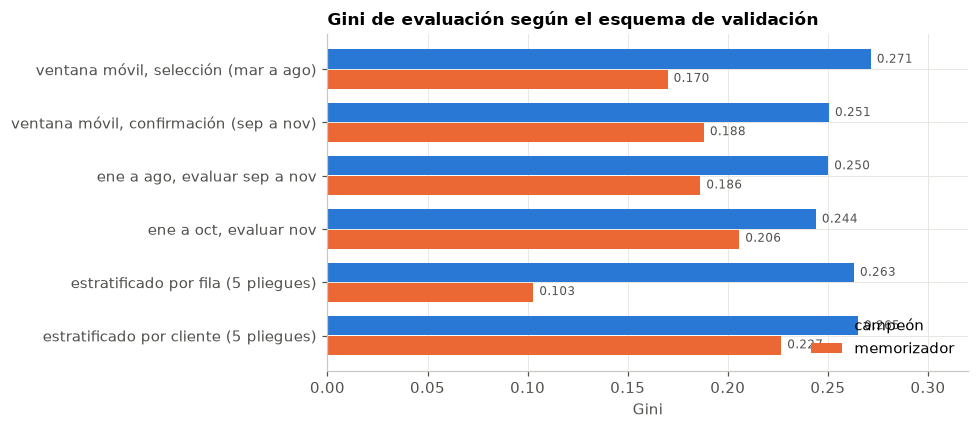

In [20]:
pv = esq.pivot(index='esquema', columns='modelo', values='gini_evaluacion').loc[list(esquemas)]
fig, ax = plt.subplots(figsize=(9, 4))
y_ = np.arange(len(pv)); h = 0.36
ax.barh(y_ - h / 2 - 0.01, pv['campeón'], height=h, color=AZUL, label='campeón')
ax.barh(y_ + h / 2 + 0.01, pv['memorizador'], height=h, color=NARANJA, label='memorizador')
for i, (a_, b_) in enumerate(zip(pv['campeón'], pv['memorizador'])):
    ax.text(a_ + 0.003, i - h / 2, f'{a_:.3f}', va='center', fontsize=8, color=TINTA2)
    ax.text(b_ + 0.003, i + h / 2, f'{b_:.3f}', va='center', fontsize=8, color=TINTA2)
ax.set_yticks(y_, pv.index); ax.invert_yaxis(); ax.legend(loc='lower right')
ax.set(title='Gini de evaluación según el esquema de validación', xlabel='Gini', xlim=(0, 0.32))
fig.tight_layout(); guardar(fig, 'A08_esquemas_validacion')

**Lectura de la figura A08.** El campeón obtiene un Gini parecido en todos los esquemas (entre 0,244 y 0,272): las diferencias dependen sobre todo de qué meses se evalúan. El Gini de entrenamiento (entre 0,29 y 0,31) no mide desempeño; su brecha con la evaluación mide sobreajuste, pequeña en el campeón y enorme en el memorizador (0,89 frente a 0,17).

Los esquemas aleatorios se equivocan con el memorizador en direcciones opuestas. La validación por fila lo castiga de más (0,103), porque las filas futuras del cliente quedan en entrenamiento y revelan que no convirtió. La validación por cliente lo sobreestima (0,227), porque evalúa clientes nunca vistos, mientras que en diciembre el 81 por ciento de los clientes ya estuvo en entrenamiento. La ventana móvil reproduce la situación de diciembre y por eso es el protocolo de todo el notebook.

## 7. Ruido de medición y techo teórico

Dos preguntas definen si vale la pena seguir buscando: cuánto se mueve el Gini solo por azar y qué Gini lograría un modelo que conociera la probabilidad verdadera de cada cliente.

* Error estándar: bootstrap por cliente del Gini medio de confirmación.
* Autoconsistencia: si las probabilidades del campeón, recalibradas, fueran la verdad, se simulan objetivos con esas probabilidades y se calcula el Gini esperado. Si coincide con el observado, el modelo ya extrae toda la señal que su propia escala permite.

In [21]:
rng = np.random.default_rng(0)
yc = np.concatenate([base[m][0] for m in CONF]); pc = np.concatenate([base[m][1] for m in CONF]); idc = np.concatenate([base[m][2] for m in CONF])
mc_ = np.concatenate([np.full(len(base[m][0]), m) for m in CONF])
u, inv = np.unique(idc, return_inverse=True)
bs = []
for _ in range(400):
    w = np.bincount(rng.integers(0, len(u), len(u)), minlength=len(u))[inv]
    bs.append(np.mean([2 * roc_auc_score(yc[mc_ == m], pc[mc_ == m], sample_weight=w[mc_ == m]) - 1 for m in CONF]))
bs = np.array(bs)
cal = np.concatenate([IsotonicRegression(out_of_bounds='clip').fit(base[m][1], base[m][0]).predict(base[m][1]) for m in CONF])
sim = [np.mean([gini(rng.random((mc_ == m).sum()) < cal[mc_ == m], pc[mc_ == m]) for m in CONF]) for _ in range(300)]
ruido = pd.Series({'gini_confirmacion': rb['gini_confirmacion'], 'error_estandar': bs.std(), 'ic95_inferior': np.percentile(bs, 2.5),
                   'ic95_superior': np.percentile(bs, 97.5), 'gini_esperado_si_p_fuera_verdad': np.mean(sim)})
ruido.to_csv(ART / 'A09_ruido_y_techo.csv'); ruido.round(4)

gini_confirmacion                  0.2508
error_estandar                     0.0087
ic95_inferior                      0.2317
ic95_superior                      0.2674
gini_esperado_si_p_fuera_verdad    0.2619
dtype: float64

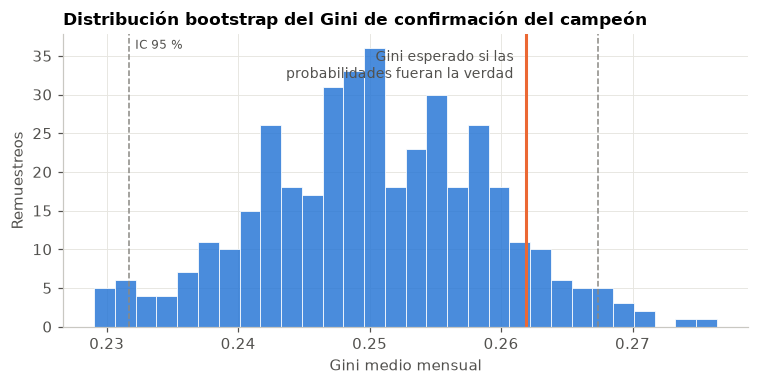

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(bs, bins=30, color=AZUL, alpha=0.85, edgecolor='white', linewidth=0.6)
for v, txt in [(ruido.ic95_inferior, 'IC 95 %'), (ruido.ic95_superior, '')]:
    ax.axvline(v, color=GRIS, ls='--', lw=1)
ax.axvline(ruido.gini_esperado_si_p_fuera_verdad, color=NARANJA, lw=2)
ax.annotate('Gini esperado si las\nprobabilidades fueran la verdad', (ruido.gini_esperado_si_p_fuera_verdad, ax.get_ylim()[1] * 0.85),
            xytext=(-8, 0), textcoords='offset points', color=TINTA2, fontsize=9, ha='right')
ax.annotate('IC 95 %', (ruido.ic95_inferior, ax.get_ylim()[1] * 0.95), xytext=(4, 0), textcoords='offset points', color=TINTA2, fontsize=8)
ax.set(title='Distribución bootstrap del Gini de confirmación del campeón', xlabel='Gini medio mensual', ylabel='Remuestreos')
fig.tight_layout(); guardar(fig, 'A09_ruido_y_techo')

**Lectura de la figura A09.** El error estándar del Gini de confirmación es 0,0087, con un intervalo de confianza del 95 por ciento entre 0,232 y 0,267. Cualquier diferencia menor que 0,01 entre dos modelos es indistinguible del azar sin una prueba pareada. Si las probabilidades del campeón fueran la verdad, el Gini esperado sería 0,262, apenas 0,011 por encima del observado: el modelo ya extrae casi toda la señal que su propia escala permite.

## 8. Ablación de fuga de datos

Esta sección no busca un modelo para entregar. Mide cuánto infla el Gini cada forma de fuga y comprueba si alguna sería aprovechable en diciembre. Todas las variables de esta sección usan información posterior al mes que se predice y quedan prohibidas en el modelo final.

Se entrena con enero a agosto y se evalúa en septiembre a noviembre.

In [23]:
def reglas(d):
    lo, hi = (d.banda_riesgo == 'low').astype(int), (d.banda_riesgo == 'high').astype(int)
    d['b_low'], d['b_high'] = lo, hi
    d['r_hi_stale'] = hi * (d.dias_ultima_transaccion > 180)
    d['r_low_p3'] = lo * (d.numero_productos >= 3)
    d['r_low_mt'] = lo * d.activo_movil * d.tiene_tarjeta_credito
    d['r_ratio_nomov'] = (d.ratio_deuda_ingresos > 0.55) * (1 - d.activo_movil)
    d['rec_lin'] = d.dias_ultima_transaccion / 365
    d['rec_low'] = lo * d.rec_lin; d['rec_notlow'] = (1 - lo) * (1 - hi) * d.rec_lin
    d['rec_hi_fresh'] = hi * (d.dias_ultima_transaccion <= 180) * d.rec_lin
    d['prod'] = np.minimum(d.numero_productos, 5); d['mov'] = d.activo_movil; d['card'] = d.tiene_tarjeta_credito
    d['mt'] = d.activo_movil * d.tiene_tarjeta_credito
    return d
al = reglas(al); lab = reglas(lab)
RULES = ['b_low', 'b_high', 'r_hi_stale', 'r_low_p3', 'r_low_mt', 'r_ratio_nomov', 'rec_low', 'rec_notlow', 'rec_hi_fresh', 'prod', 'mov', 'card', 'mt']
SIX = ['banda_riesgo', 'numero_productos', 'dias_ultima_transaccion', 'activo_movil', 'tiene_tarjeta_credito', 'ratio_deuda_ingresos']
SIXN = ['b_low', 'b_high', 'numero_productos', 'dias_ultima_transaccion', 'activo_movil', 'tiene_tarjeta_credito', 'ratio_deuda_ingresos']
F6R = list(dict.fromkeys(SIXN + RULES))

gq = al.groupby('id_cliente')
al['FUGA_ultima_aparicion'] = (al.t == gq.t.transform('max')).astype(int)
al['FUGA_meses_restantes'] = gq.t.transform('max') - al.t
al['FUGA_apariciones_totales'] = gq.t.transform('size')
al['FUGA_sale_antes_de_dic'] = (gq.t.transform('max') < 12).astype(int)
al['PASADO_apariciones'] = al.h_k + 1
lf = al[al.objetivo.notna()]; a8, o9 = lf[lf.t <= 8], lf[lf.t >= 9]; dic = al[al.t == 12]
ajf = lambda f: lgb.LGBMClassifier(**CHP).fit(a8[f], a8.objetivo).predict_proba(o9[f])[:, 1]
fuga = [('sin fuga (6 variables y reglas)', gini(o9.objetivo, ajf(F6R)), 'sí')]
for v, txt in [('PASADO_apariciones', 'apariciones pasadas (legítima)'), ('FUGA_apariciones_totales', 'apariciones totales'),
               ('FUGA_sale_antes_de_dic', 'el cliente sale antes de diciembre'), ('FUGA_meses_restantes', 'meses restantes en el panel'),
               ('FUGA_ultima_aparicion', 'última aparición del cliente')]:
    fuga.append((txt, gini(o9.objetivo, ajf(F6R + [v])), f'{dic[v].nunique()} valores distintos'))
oof = np.zeros(len(lf)); lfr = lf.reset_index(drop=True)
for a, b in StratifiedKFold(5, shuffle=True, random_state=0).split(lfr, lfr.objetivo):
    m = lgb.LGBMClassifier(**CHP).fit(lfr.iloc[a][F6R + ['FUGA_apariciones_totales']], lfr.iloc[a].objetivo)
    oof[b] = m.predict_proba(lfr.iloc[b][F6R + ['FUGA_apariciones_totales']])[:, 1]
fuga.append(('validación cruzada aleatoria por fila', gini(lfr.objetivo, oof), 'no aplica'))
fuga.append(('codificación por target del cliente', gini(lf.objetivo, lf.groupby('id_cliente').objetivo.transform('mean')), 'no calculable'))
fuga = pd.DataFrame(fuga, columns=['variante', 'gini', 'disponible_en_diciembre']).set_index('variante')
fuga.to_csv(ART / 'A10_ablacion_fuga.csv'); fuga.round(4)

,gini,disponible_en_diciembre
variante,,
sin fuga (6 variables y reglas),0.2511,sí
apariciones pasadas (legítima),0.2501,12 valores distintos
apariciones totales,0.3088,12 valores distintos
el cliente sale antes de diciembre,0.8656,1 valores distintos
meses restantes en el panel,1.0000,1 valores distintos
última aparición del cliente,1.0000,1 valores distintos
validación cruzada aleatoria por fila,0.6716,no aplica
codificación por target del cliente,0.7739,no calculable


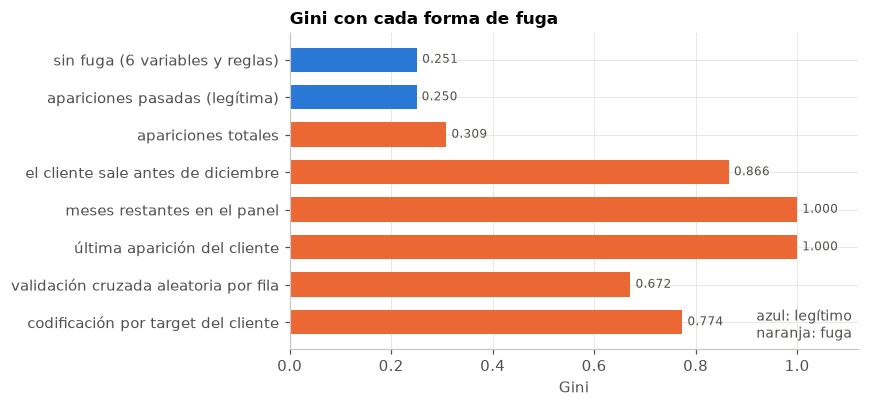

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.8))
f_ = fuga.iloc[::-1]
legit = f_.index.isin(['sin fuga (6 variables y reglas)', 'apariciones pasadas (legítima)'])
ax.barh(f_.index, f_.gini, color=[AZUL if l else NARANJA for l in legit], height=0.65)
for i, v in enumerate(f_.gini):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=8, color=TINTA2)
ax.set(title='Gini con cada forma de fuga', xlabel='Gini', xlim=(0, 1.12))
ax.text(0.99, 0.02, 'azul: legítimo\nnaranja: fuga', transform=ax.transAxes, ha='right', va='bottom', color=TINTA2, fontsize=9)
fig.tight_layout(); guardar(fig, 'A10_ablacion_fuga')

**Lectura de la figura A10.** Toda forma de fuga dispara el Gini (entre 0,31 y 1,00), y ninguna sirve en diciembre:

* Las variables que miran el futuro del cliente (última aparición, meses restantes y salida antes de diciembre) son constantes en diciembre, porque es el último mes del panel.
* La parte legítima de las apariciones totales, el conteo de meses pasados, no aporta (0,250 frente a 0,251 sin fuga). Toda la ganancia hasta 0,309 viene de la parte futura.
* La validación aleatoria por fila (0,672) y la codificación por target del cliente (0,774) son fugas de evaluación que no existen al puntuar.

Conclusión: un Gini mayor que 0,5 en validación solo se logra con fuga y caería a cerca de 0,25 en el leaderboard.

## 9. Experimentos de mejora

Se prueban cinco familias de ideas, todas con el protocolo de la sección 6:

* A. Selección de variables: solo las seis variables reales, reglas explícitas del generador y la variable de interacción.
* B. Historial, tendencia y velocidad: permanencia en el panel y ventanas de 3, 6 y 9 meses (media, mínimo, máximo, desviación, pendiente, número de cambios, velocidad y aceleración). Todas se calculan solo con el mes actual y los anteriores.
* C. Modelos y funciones de pérdida: pérdida focal, pérdida de ranking por pares, árboles, bosques, red neuronal, modelo aditivo y modelo con interacciones restringidas, pesos por recencia y por cliente.
* D. Segmentación, población y target: un modelo por banda, canal o producto; entrenar solo con recurrentes o con los últimos meses; target de conversión en tres meses. Para este target solo se usan filas cuya ventana de tres meses está completa dentro del entrenamiento; en el corte de marzo, que solo tiene dos meses de historia, la ventana se reduce a dos meses.
* E. Representaciones de las seis variables: tabla de celdas con suavizado jerárquico y logística saturada.

In [25]:
x_ = 'dias_ultima_interaccion'
gi = al.groupby('id_cliente')
al['i_cambio'] = ((al[x_] != gi[x_].shift()) & gi[x_].shift().notna()).astype(int)
gi = al.groupby('id_cliente')
for w in (3, 6, 9):
    r_ = gi[x_].rolling(w, min_periods=1)
    al[f'v_media_{w}'] = r_.mean().reset_index(level=0, drop=True)
    al[f'v_min_{w}'] = r_.min().reset_index(level=0, drop=True)
    al[f'v_max_{w}'] = r_.max().reset_index(level=0, drop=True)
    al[f'v_std_{w}'] = gi[x_].rolling(w, min_periods=2).std().reset_index(level=0, drop=True)
    al[f'v_pend_{w}'] = gi[x_].rolling(w, min_periods=2).apply(lambda s: np.polyfit(np.arange(len(s)), s, 1)[0], raw=True).reset_index(level=0, drop=True)
    al[f'v_ncambios_{w}'] = gi.i_cambio.rolling(w, min_periods=1).sum().reset_index(level=0, drop=True)
al['v_velocidad'] = gi[x_].diff(); al['v_aceleracion'] = al.groupby('id_cliente').v_velocidad.diff()
TEND = [c for c in al.columns if c.startswith('v_')]
lab = al[al.objetivo.notna()].copy()
print(len(TEND), 'variables de historial, tendencia y velocidad')

20 variables de historial, tendencia y velocidad


In [26]:
def focal(gamma=1.0):
    def obj(y, raw):
        p = 1 / (1 + np.exp(-raw)); pt = np.where(y == 1, p, 1 - p); w = (1 - pt) ** gamma
        return w * (p - y), np.maximum(w * p * (1 - p), 1e-6)
    return obj
def xgb_rank(a, b, f):
    a = a.sort_values('t')
    m = xgb.XGBRanker(objective='rank:pairwise', max_depth=3, n_estimators=400, learning_rate=0.02, min_child_weight=50, subsample=0.7,
                      lambdarank_num_pair_per_sample=8, lambdarank_pair_method='mean', random_state=0)
    return m.fit(codificar(a, f), a.objetivo.astype(int), qid=a.t.values).predict(codificar(b, f))
def por_segmento(col, **k):
    def ajuste(a, b, f):
        out = np.zeros(len(b))
        for s in b[col].unique():
            ma, mb = (a[col] == s).values, (b[col] == s).values
            out[mb] = lgb.LGBMClassifier(**{**CHP, 'scale_pos_weight': 1, **k}).fit(a[ma][f], a[ma].objetivo).predict_proba(b[mb][f])[:, 1]
        return out
    return ajuste
def subpoblacion(cond):
    return lambda a, b, f: lgb.LGBMClassifier(**CHP).fit(a[cond(a)][f], a[cond(a)].objetivo).predict_proba(b[f])[:, 1]
def target_3_meses(a, b, f):
    conv = a[a.objetivo == 1].groupby('id_cliente').t.min()
    ct = a.id_cliente.map(conv).fillna(99)
    h = min(3, int(a.t.max()))  # horizonte de 3 meses; en el primer corte solo hay 2 meses de historia
    a = a.assign(y3=((ct >= a.t) & (ct <= a.t + h - 1)).astype(int))
    a = a[a.t <= a.t.max() - (h - 1)]
    return lgb.LGBMClassifier(**{**CHP, 'scale_pos_weight': 1}).fit(a[f], a.y3).predict_proba(b[f])[:, 1]
peso_cliente = lambda a: 1 / a.groupby('id_cliente').t.transform('size')
peso_recencia = lambda a: 0.85 ** (a.t.max() - a.t)
ic = [[0, 1, 2], [0, 1, 3], [0, 1, 4], [4, 5], [4, 6]]
FSIN = [c for c in CHAMP if c != 'canal_adquisicion']
EXPERIMENTOS = [
    ('A', 'LGBM 21 variables originales', lgbm(CHP), BASE, True),
    ('A', 'LGBM 21 variables y dias_ultima_interaccion', lgbm(CHP), BASE + ['dias_ultima_interaccion'], True),
    ('A', 'LGBM solo 6 variables reales', lgbm(CHP), SIXN, True),
    ('A', 'LGBM 6 variables y reglas', lgbm(CHP), F6R, True),
    ('A', 'Logística con 13 términos de reglas', skl(lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))), RULES, True),
    ('B', 'Campeón y permanencia en el panel', lgbm(CHP), CHAMP + ['h_k', 'h_jan'], True),
    ('B', 'Campeón y ventanas 3, 6, 9 con tendencia y velocidad', lgbm(CHP), CHAMP + TEND, True),
    ('C', 'LGBM pérdida focal', lgbm({**CHP, 'objective': focal(1.0), 'scale_pos_weight': 1}), F6R, False),
    ('C', 'XGB pérdida de ranking por pares', xgb_rank, F6R, False),
    ('C', 'XGB pérdida logística', skl(lambda: xgb.XGBClassifier(max_depth=3, n_estimators=500, learning_rate=0.01, min_child_weight=60, subsample=0.7, reg_lambda=3, n_jobs=8, random_state=0)), F6R, True),
    ('C', 'CatBoost 6 variables nativas', catboost(4, 800, 0.02), SIX, True),
    ('C', 'Árbol de decisión, hojas de 800', skl(lambda: DecisionTreeClassifier(min_samples_leaf=800, max_depth=6, random_state=0)), SIXN, True),
    ('C', 'Bosque aleatorio, hojas de 300', skl(lambda: RandomForestClassifier(500, min_samples_leaf=300, max_features=0.6, n_jobs=8, random_state=0)), SIXN, True),
    ('C', 'Red neuronal 16 y 8', skl(lambda: make_pipeline(StandardScaler(), MLPClassifier((16, 8), alpha=1e-2, max_iter=300, early_stopping=True, random_state=0))), F6R, True),
    ('C', 'LGBM aditivo puro (profundidad 1)', lgbm({**CHP, 'max_depth': 1, 'num_leaves': 2, 'n_estimators': 1500, 'learning_rate': 0.02}), SIXN, True),
    ('C', 'LGBM con interacciones de a pares', lgbm({**CHP, 'interaction_constraints': ic}), SIXN, True),
    ('C', 'LGBM peso 1 entre filas del cliente', lgbm(CHP, peso=peso_cliente), F6R, True),
    ('C', 'LGBM peso por recencia', lgbm(CHP, peso=peso_recencia), F6R, True),
    ('D', 'Un LGBM por banda de riesgo', por_segmento('banda_riesgo', min_child_samples=300), [c for c in CHAMP if c != 'banda_riesgo'], True),
    ('D', 'Un LGBM por canal de adquisición', por_segmento('canal_adquisicion', min_child_samples=200), FSIN, True),
    ('D', 'Un LGBM por tenencia de préstamo', por_segmento('tiene_prestamo', min_child_samples=300), FSIN, True),
    ('D', 'Target de conversión en tres meses', target_3_meses, CHAMP, True),
    ('D', 'Entrenar solo con recurrentes', subpoblacion(lambda a: a.h_k > 0), CHAMP, True),
    ('D', 'Entrenar solo con los últimos 5 meses', subpoblacion(lambda a: a.t > a.t.max() - 5), CHAMP, True),
]
t0 = time.time()
for grp, nombre, aj, ff, prob in EXPERIMENTOS:
    registrar(nombre, wf(nombre, aj, ff), grp, prob)
print(f'{time.time() - t0:.0f} s')

LGBM 21 variables originales                               sel=0.2633 conf=0.2515 ks=0.162 f1=0.286 min=0.2382  < mejor solo en confirmación (no basta)


LGBM 21 variables y dias_ultima_interaccion                sel=0.2615 conf=0.2516 ks=0.160 f1=0.286 min=0.2384  < mejor solo en confirmación (no basta)


LGBM solo 6 variables reales                               sel=0.2601 conf=0.2499 ks=0.160 f1=0.283 min=0.2330


LGBM 6 variables y reglas                                  sel=0.2621 conf=0.2514 ks=0.162 f1=0.283 min=0.2378  < mejor solo en confirmación (no basta)


Logística con 13 términos de reglas                        sel=0.2556 conf=0.2497 ks=0.163 f1=0.287 min=0.2401


...

Un LGBM por canal de adquisición                           sel=0.2518 conf=0.2399 ks=0.150 f1=0.283 min=0.2319


Un LGBM por tenencia de préstamo                           sel=0.2647 conf=0.2460 ks=0.159 f1=0.285 min=0.2359


Target de conversión en tres meses                         sel=0.2691 conf=0.2485 ks=0.157 f1=0.278 min=0.2409


Entrenar solo con recurrentes                              sel=0.2680 conf=0.2483 ks=0.154 f1=0.282 min=0.2399


Entrenar solo con los últimos 5 meses                      sel=0.2718 conf=0.2488 ks=0.156 f1=0.287 min=0.2374  << mejor solo en selección
395 s


In [27]:
al['c_band'] = al.banda_riesgo.astype(str); al['c_prod'] = np.minimum(al.numero_productos, 3)
al['c_rec'] = pd.cut(al.dias_ultima_transaccion, [0, 90, 180, 365], labels=False); al['c_mov'] = al.activo_movil
al['c_card'] = al.tiene_tarjeta_credito; al['c_rat'] = (al.ratio_deuda_ingresos > 0.55).astype(int)
CELDA = ['c_band', 'c_prod', 'c_rec', 'c_mov', 'c_card', 'c_rat']
lab = al[al.objetivo.notna()].copy()
def celdas(k=200):
    niveles = [['c_band'], ['c_band', 'c_prod'], ['c_band', 'c_prod', 'c_rec'], ['c_band', 'c_prod', 'c_rec', 'c_mov', 'c_card'], CELDA]
    def ajuste(a, b, f):
        previa = pd.Series(a.objetivo.mean(), index=b.index)
        for nv in niveles:
            est = a.groupby(nv).objetivo.agg(['sum', 'count'])
            clave = pd.MultiIndex.from_frame(b[nv]) if len(nv) > 1 else pd.Index(b[nv[0]])
            s = pd.Series(est['sum'].reindex(clave).values, index=b.index).fillna(0)
            n = pd.Series(est['count'].reindex(clave).values, index=b.index).fillna(0)
            previa = (s + k * previa) / (n + k)
        return previa.values
    return ajuste
saturada = skl(lambda: make_pipeline(OneHotEncoder(handle_unknown='ignore'), PolynomialFeatures(3, interaction_only=True, include_bias=False), LogisticRegression(C=0.01, max_iter=4000)))
for nombre, aj in [('Tabla de celdas con suavizado jerárquico', celdas(200)), ('Logística saturada de grado 3 sobre celdas', saturada)]:
    registrar(nombre, wf(nombre, aj, CELDA), 'E')

Tabla de celdas con suavizado jerárquico                   sel=0.2521 conf=0.2494 ks=0.161 f1=0.287 min=0.2422


Logística saturada de grado 3 sobre celdas                 sel=0.2545 conf=0.2515 ks=0.160 f1=0.288 min=0.2404  < mejor solo en confirmación (no basta)


In [28]:
tabla = pd.DataFrame(RES).drop_duplicates('modelo', keep='last')
tabla.to_csv(ART / 'A11_experimentos.csv', index=False)
tabla[['grupo', 'modelo', 'gini_seleccion', 'gini_confirmacion', 'std_mensual', 'gini_minimo', 'ks_confirmacion', 'f1_confirmacion',
       'pr_auc_confirmacion', 'brier_confirmacion']].sort_values('gini_seleccion', ascending=False).round(4)

,grupo,modelo,gini_seleccion,gini_confirmacion,std_mensual,gini_minimo,ks_confirmacion,f1_confirmacion,pr_auc_confirmacion,brier_confirmacion
24,D,Entrenar solo con los últimos 5 meses,0.2718,0.2488,0.0137,0.2374,0.1555,0.2868,0.2349,0.1264
0,referencia,"campeón LGBM 12 variables, 5 semillas",0.2714,0.2508,0.0122,0.2435,0.1569,0.2850,0.2363,0.1267
6,B,Campeón y permanencia en el panel,0.2713,0.2508,0.0117,0.2429,0.1575,0.2841,0.2366,0.1265
22,D,Target de conversión en tres meses,0.2691,0.2485,0.0125,0.2409,0.1573,0.2776,0.2351,0.1697
23,D,Entrenar solo con recurrentes,0.2680,0.2483,0.0120,0.2399,0.1540,0.2822,0.2365,0.1265
7,B,"Campeón y ventanas 3, 6, 9 con tendencia y vel...",0.2673,0.2513,0.0109,0.2423,0.1579,0.2839,0.2362,0.1265
21,D,Un LGBM por tenencia de préstamo,0.2647,0.2460,0.0128,0.2359,0.1591,0.2855,0.2350,0.1231
19,D,Un LGBM por banda de riesgo,0.2634,0.2470,0.0138,0.2352,0.1558,0.2856,0.2349,0.1230
1,A,LGBM 21 variables originales,0.2633,0.2515,0.0090,0.2382,0.1616,0.2856,0.2356,0.1268
4,A,LGBM 6 variables y reglas,0.2621,0.2514,0.0090,0.2378,0.1624,0.2825,0.2377,0.1266


**Lectura de la tabla de experimentos.** Ninguna de las cinco familias supera al campeón en selección y confirmación a la vez:

* Empatan con el campeón, dentro del ruido: la permanencia en el panel (0,2713 en selección y 0,2508 en confirmación) y entrenar con los últimos cinco meses (0,2718 en selección, pero 0,2488 en confirmación).
* Quedan entre 0,002 y 0,025 por debajo en selección: solo las seis variables reales, la logística de reglas, las pérdidas focal y de ranking, los árboles y bosques, la segmentación por banda, canal o préstamo, el target de tres meses y las representaciones por celdas.
* Fallan con claridad: la red neuronal (0,213), el modelo aditivo puro (0,239) y el modelo con interacciones de a pares (0,255), porque el generador tiene interacciones de orden tres.
* Las ventanas de 3, 6 y 9 meses con tendencia y velocidad empeoran la selección (0,2673), como anticipaba la auditoría: no hay una serie temporal que resumir.

Varios modelos mejoran solo la confirmación; según la regla de decisión, eso no basta.

## 10. Plan de mejora dirigido

Plan en siete pasos, todos con el protocolo de la sección 6:

1. Variables dirigidas sobre las tres variables más fuertes: interacciones entre banda, productos y recencia, umbrales de 30, 90 y 180 días y tramos. Se prueban con solo esas tres variables (dir3), con las seis reales (dir6), con las del campeón más dir6 y con variables de mes y cohorte.
2. Cinco modelos: logística sobre tramos, LightGBM, XGBoost, CatBoost y ExtraTrees.
3. Búsqueda pequeña de LightGBM (40 configuraciones al azar), elegida solo con el tramo de selección.
4. LightGBM con restricciones monótonas donde el signo tiene sentido de negocio.
5. LightGBM de seis variables ajustado con Optuna.
6. Ensamble E1 (promedio de rangos de siete modelos) y mezcla por rangos con pesos elegidos solo en selección.
7. Bootstrap pareado contra el campeón.

Las variables de mes y cohorte se calculan con las filas del propio mes, sin usar el objetivo, por lo que estarían disponibles al puntuar diciembre. Aun así, son constantes dentro de un mismo mes y solo podrían cambiar el orden mediante interacciones.

In [29]:
bo = al.banda_riesgo.map({'high': 0, 'medium': 1, 'low': 2}).astype(int); pr_ = al.numero_productos; dt_ = al.dias_ultima_transaccion
al['b_ord'] = bo; al['bxp'] = bo * pr_; al['bxd'] = bo * dt_; al['pxd'] = pr_ * dt_
for k in (30, 90, 180):
    al[f'd_gt{k}'] = (dt_ > k).astype(int)
al['d_bin'] = pd.cut(dt_, [0, 30, 90, 180, 270, 365], labels=False).astype(int); al['p_bin'] = np.minimum(pr_, 3)
al['bxpbin'] = bo * 3 + al.p_bin; al['bxdbin'] = bo * 5 + al.d_bin
al['hi_gt180'] = (bo == 0) * (dt_ > 180); al['lo_p3'] = (bo == 2) * (pr_ >= 3)
al['lo_mt'] = (bo == 2) * al.activo_movil * al.tiene_tarjeta_credito
al['rat55_nomov'] = (al.ratio_deuda_ingresos > 0.55) * (1 - al.activo_movil)
gm_ = al.groupby('t')
al['m_n'] = gm_.id_cliente.transform('size'); al['m_sh_low'] = gm_.b_ord.transform(lambda s: (s == 2).mean())
al['m_sh_hi'] = gm_.b_ord.transform(lambda s: (s == 0).mean()); al['m_sh_p3'] = gm_.numero_productos.transform(lambda s: (s >= 3).mean())
al['m_sh_new'] = gm_.h_new.transform('mean'); al['bxmes'] = bo * al.t; al['pxmes'] = pr_ * al.t
lab = al[al.objetivo.notna()].copy()
FS = {}
FS['dir3'] = ['b_ord', 'numero_productos', 'dias_ultima_transaccion', 'bxp', 'bxd', 'pxd', 'd_gt30', 'd_gt90', 'd_gt180', 'd_bin', 'p_bin', 'bxpbin', 'bxdbin', 'hi_gt180', 'lo_p3']
FS['dir6'] = FS['dir3'] + ['activo_movil', 'tiene_tarjeta_credito', 'ratio_deuda_ingresos', 'mt', 'lo_mt', 'rat55_nomov']
FS['campeón y dir6'] = list(dict.fromkeys(CHAMP + FS['dir6']))
FS['dir6 y mes'] = FS['dir6'] + ['t', 'bxmes', 'pxmes', 'm_n', 'm_sh_low', 'm_sh_hi', 'm_sh_p3', 'm_sh_new', 'h_k', 'h_jan']
FS['campeón 12'] = CHAMP

def lr_tramos(a, b, f):
    num = [c for c in f if a[c].nunique() > 8]; oth = [c for c in f if c not in num]
    ct = ColumnTransformer([('n', KBinsDiscretizer(8, encode='onehot', strategy='quantile'), num), ('o', OneHotEncoder(handle_unknown='ignore'), oth)])
    X = lambda d: d[f].astype({c: str for c in f if c in CAT})
    return make_pipeline(ct, LogisticRegression(C=0.05, max_iter=4000)).fit(X(a), a.objetivo).predict_proba(X(b))[:, 1]
XGBF = skl(lambda: xgb.XGBClassifier(max_depth=3, n_estimators=500, learning_rate=0.01, min_child_weight=60, subsample=0.7, reg_lambda=3, n_jobs=8, random_state=0))
MODELOS = {'Logística sobre tramos': lr_tramos, 'LGBM': lgbm(CHP), 'XGB': XGBF, 'CatBoost': catboost(),
           'ExtraTrees': skl(lambda: ExtraTreesClassifier(400, min_samples_leaf=200, max_features=0.7, n_jobs=8, random_state=0))}
t0 = time.time()
for fsn in ['dir3', 'dir6', 'campeón y dir6', 'dir6 y mes', 'campeón 12']:
    for mn, aj in MODELOS.items():
        if fsn == 'campeón 12' and mn == 'LGBM': continue
        nombre = f'{mn} con {fsn}'
        registrar(nombre, wf(nombre, aj, FS[fsn]), 'F')
print(f'{time.time() - t0:.0f} s')

Logística sobre tramos con dir3                            sel=0.2442 conf=0.2295 ks=0.153 f1=0.286 min=0.2075


LGBM con dir3                                              sel=0.2470 conf=0.2302 ks=0.152 f1=0.288 min=0.2078


XGB con dir3                                               sel=0.2463 conf=0.2308 ks=0.153 f1=0.288 min=0.2092


CatBoost con dir3                                          sel=0.2408 conf=0.2294 ks=0.150 f1=0.285 min=0.2094


ExtraTrees con dir3                                        sel=0.2401 conf=0.2222 ks=0.143 f1=0.282 min=0.2013


...

ExtraTrees con dir6 y mes                                  sel=0.2553 conf=0.2530 ks=0.163 f1=0.281 min=0.2372  < mejor solo en confirmación (no basta)


Logística sobre tramos con campeón 12                      sel=0.2504 conf=0.2318 ks=0.152 f1=0.282 min=0.2148


XGB con campeón 12                                         sel=0.2719 conf=0.2510 ks=0.157 f1=0.285 min=0.2445  <<< SUPERA al campeón en selección y confirmación


CatBoost con campeón 12                                    sel=0.2682 conf=0.2481 ks=0.157 f1=0.281 min=0.2422


ExtraTrees con campeón 12                                  sel=0.2612 conf=0.2447 ks=0.153 f1=0.285 min=0.2360
954 s


In [30]:
FCD = FS['campeón y dir6']
rng = np.random.default_rng(7); pruebas = []
for i in range(40):
    p = dict(objective='binary', verbose=-1, n_jobs=8, subsample_freq=1, random_state=0,
             num_leaves=int(rng.choice([4, 6, 8, 12, 16, 24])), max_depth=int(rng.choice([2, 3, 4, 5])),
             min_child_samples=int(rng.choice([100, 200, 400, 700, 1000, 1500])), learning_rate=float(rng.choice([0.005, 0.01, 0.02, 0.03])),
             colsample_bytree=float(rng.uniform(0.5, 1)), subsample=float(rng.uniform(0.5, 1)),
             reg_alpha=float(10 ** rng.uniform(-2, 1)), reg_lambda=float(10 ** rng.uniform(-2, 1.5)))
    p['n_estimators'] = int(round(6 / p['learning_rate'] / 50) * 50)
    gs = [gini(lab[lab.t == m].objetivo, lgb.LGBMClassifier(**p).fit(lab[lab.t < m][FCD], lab[lab.t < m].objetivo).predict_proba(lab[lab.t == m][FCD])[:, 1]) for m in SEL]
    pruebas.append((np.mean(gs) - 0.5 * np.std(gs), p))
PBUS = max(pruebas, key=lambda x: x[0])[1]
json.dump(PBUS, open(ART / 'A12_lgbm_busqueda_parametros.json', 'w'), indent=1)
registrar('LGBM búsqueda de 40 configuraciones con campeón y dir6', wf('LGBM búsqueda', lgbm(PBUS), FCD), 'G')

signo = {'b_ord': 1, 'numero_productos': 1, 'dias_ultima_transaccion': -1, 'activo_movil': 1, 'tiene_tarjeta_credito': 1, 'ratio_deuda_ingresos': -1,
         'productos_x_riesgo_bajo': 1, 'movil_y_tarjeta': 1, 'lo_p3': 1, 'lo_mt': 1, 'hi_gt180': -1, 'rat55_nomov': -1}
MC = [signo.get(c, 0) for c in FCD]
registrar('LGBM monótono con parámetros del campeón', wf('LGBM monótono campeón', lgbm({**CHP, 'monotone_constraints': MC}), FCD), 'G')
registrar('LGBM monótono con parámetros de la búsqueda', wf('LGBM monótono búsqueda', lgbm({**PBUS, 'monotone_constraints': MC}), FCD), 'G')

def objetivo_optuna(tr_):
    p = dict(objective='binary', verbose=-1, n_jobs=8, subsample_freq=1, random_state=0,
             learning_rate=tr_.suggest_float('lr', 0.005, 0.05, log=True), n_estimators=tr_.suggest_int('n', 150, 1200, step=50),
             max_depth=tr_.suggest_int('md', 2, 5), num_leaves=tr_.suggest_int('nl', 4, 24), min_child_samples=tr_.suggest_int('mcs', 100, 1500, log=True),
             subsample=tr_.suggest_float('ss', 0.5, 1), colsample_bytree=tr_.suggest_float('cs', 0.5, 1), reg_lambda=tr_.suggest_float('l2', 0.01, 30, log=True))
    gs = [gini(lab[lab.t == m].objetivo, lgb.LGBMClassifier(**p).fit(lab[lab.t < m][SIXN], lab[lab.t < m].objetivo).predict_proba(lab[lab.t == m][SIXN])[:, 1]) for m in SEL]
    return np.mean(gs) - 0.5 * np.std(gs)
estudio = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0)); estudio.optimize(objetivo_optuna, n_trials=40)
b_ = estudio.best_params
P6 = dict(objective='binary', verbose=-1, n_jobs=8, subsample_freq=1, random_state=0, learning_rate=b_['lr'], n_estimators=b_['n'], max_depth=b_['md'],
          num_leaves=b_['nl'], min_child_samples=b_['mcs'], subsample=b_['ss'], colsample_bytree=b_['cs'], reg_lambda=b_['l2'])
json.dump(P6, open(ART / 'A13_lgbm_optuna_6_variables.json', 'w'), indent=1)
_ = registrar('LGBM 6 variables ajustado con Optuna', wf('LGBM Optuna 6', lgbm(P6), SIXN), 'G')

LGBM búsqueda de 40 configuraciones con campeón y dir6     sel=0.2731 conf=0.2500 ks=0.159 f1=0.281 min=0.2453  << mejor solo en selección


LGBM monótono con parámetros del campeón                   sel=0.2714 conf=0.2530 ks=0.159 f1=0.284 min=0.2423  < mejor solo en confirmación (no basta)


LGBM monótono con parámetros de la búsqueda                sel=0.2722 conf=0.2506 ks=0.156 f1=0.283 min=0.2451  << mejor solo en selección


LGBM 6 variables ajustado con Optuna                       sel=0.2630 conf=0.2510 ks=0.159 f1=0.286 min=0.2362  < mejor solo en confirmación (no basta)


In [31]:
MIEMBROS_E1 = {
    'lgb_campeon': ('E1 lgb_campeon', lgbm(CHP), CHAMP),
    'lgb_campeon_semillas': ('E1 lgb_campeon_semillas', lgbm({**CHP, 'scale_pos_weight': 1}, semillas=range(5)), CHAMP),
    'lgb_reglas_peso': ('LGBM peso 1 entre filas del cliente', lgbm(CHP, peso=peso_cliente), F6R),
    'xgb_reglas': ('XGB pérdida logística', XGBF, F6R),
    'cat_seis': ('CatBoost 6 variables nativas', catboost(4, 800, 0.02), SIX),
    'logit_reglas': ('Logística con 13 términos de reglas', skl(lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))), RULES),
    'rf_seis': ('Bosque aleatorio, hojas de 300', skl(lambda: RandomForestClassifier(500, min_samples_leaf=300, max_features=0.6, n_jobs=8, random_state=0)), SIXN)}
def ranks(out, m): return rankdata(out[m][1]) / len(out[m][1])
def mezcla(pesos):
    return {m: (base[m][0], sum(w * ranks(OOF[k], m) for k, w in pesos.items() if w > 0), base[m][2]) for m in MESES}
for k, (nombre, aj, ff) in MIEMBROS_E1.items():
    wf(nombre, aj, ff)
E1 = {MIEMBROS_E1[k][0]: 1 / 7 for k in MIEMBROS_E1}
OOF['Ensamble E1'] = mezcla(E1)
registrar('Ensamble E1, promedio de rangos de 7 modelos', OOF['Ensamble E1'], 'H', prob=False)

candidatos = {'campeón': 'campeón LGBM 12 variables, 5 semillas', 'xgb_cd6': 'XGB con campeón y dir6', 'lgb_cd6': 'LGBM con campeón y dir6',
              'cat_cd6': 'CatBoost con campeón y dir6', 'lr_cd6': 'Logística sobre tramos con campeón y dir6', 'xgb_c12': 'XGB con campeón 12',
              'lgb_busqueda': 'LGBM búsqueda'}
mezclas = []
for r_ in (2, 3):
    for combo in itertools.combinations(candidatos, r_):
        for ws in itertools.product([0.25, 0.5, 0.75], repeat=r_):
            if abs(sum(ws) - 1) > 1e-9: continue
            o_ = mezcla({candidatos[c]: w for c, w in zip(combo, ws)})
            mezclas.append((np.mean([gini(o_[m][0], o_[m][1]) for m in SEL]), np.mean([gini(o_[m][0], o_[m][1]) for m in CONF]), dict(zip(combo, ws))))
mezclas.sort(key=lambda x: -x[0])
print(f'{len(mezclas)} mezclas evaluadas; las cinco mejores por selección:')
for s_, c_, w_ in mezclas[:5]:
    print(f'  selección {s_:.4f}  confirmación {c_:.4f}  {w_}')
OOF['Mezcla elegida en selección'] = mezcla({candidatos[c]: w for c, w in mezclas[0][2].items()})
_ = registrar('Mezcla por rangos elegida en selección', OOF['Mezcla elegida en selección'], 'H', prob=False)

Ensamble E1, promedio de rangos de 7 modelos               sel=0.2666 conf=0.2540 ks=0.160 f1=0.289 min=0.2440  < mejor solo en confirmación (no basta)


168 mezclas evaluadas; las cinco mejores por selección:
  selección 0.2737  confirmación 0.2514  {'lgb_cd6': 0.25, 'xgb_c12': 0.25, 'lgb_busqueda': 0.5}
  selección 0.2736  confirmación 0.2505  {'xgb_c12': 0.25, 'lgb_busqueda': 0.75}
  selección 0.2736  confirmación 0.2510  {'xgb_c12': 0.5, 'lgb_busqueda': 0.5}
  selección 0.2736  confirmación 0.2512  {'xgb_cd6': 0.25, 'xgb_c12': 0.25, 'lgb_busqueda': 0.5}
  selección 0.2735  confirmación 0.2522  {'lgb_cd6': 0.5, 'xgb_c12': 0.25, 'lgb_busqueda': 0.25}


Mezcla por rangos elegida en selección                     sel=0.2737 conf=0.2514 ks=0.158 f1=0.283 min=0.2455  <<< SUPERA al campeón en selección y confirmación


In [32]:
finalistas = ['XGB con campeón y dir6', 'XGB con campeón 12', 'LGBM con campeón y dir6', 'LGBM monótono campeón', 'LGBM monótono búsqueda',
              'LGBM búsqueda', 'LGBM Optuna 6', 'Ensamble E1', 'Mezcla elegida en selección']
boot = []
for f_ in finalistas:
    for tramo, ms in [('selección', SEL), ('confirmación', CONF)]:
        md_, lo_, hi_, pm = bootstrap_pareado(OOF[f_], base, ms)
        boot.append(dict(modelo=f_, tramo=tramo, diferencia=md_, ic95_inferior=lo_, ic95_superior=hi_, prob_mejor=pm))
boot = pd.DataFrame(boot)
boot.to_csv(ART / 'A14_bootstrap_vs_campeon.csv', index=False)
boot.pivot(index='modelo', columns='tramo', values=['diferencia', 'ic95_inferior', 'ic95_superior', 'prob_mejor']).round(4)

diferencia           ic95_inferior           ic95_superior             prob_mejor          
tramo                       confirmación selección  confirmación selección  confirmación selección confirmación selección
modelo                                                                                                                   
Ensamble E1                       0.0027   -0.0047       -0.0027   -0.0088        0.0078   -0.0012       0.8200    0.0100
LGBM Optuna 6                    -0.0004   -0.0082       -0.0070   -0.0135        0.0059   -0.0036       0.4700    0.0033
LGBM búsqueda                    -0.0008    0.0017       -0.0056   -0.0016        0.0038    0.0048       0.3833    0.8233
LGBM con campeón y dir6           0.0021    0.0013       -0.0021   -0.0017        0.0062    0.0049       0.8400    0.7800
LGBM monótono búsqueda           -0.0003    0.0007       -0.0051   -0.0026        0.0044    0.0039       0.4467    0.6667
LGBM monótono campeón             0.0020   -0.0000       -0.0022   -0.0038        0.0068    0.0035       0.7967    0.4900
Mezcla elegida en selección       0.0006    0.0023       -0.0030   -0.0002        0.0040    0.0047       0.6400    0.9667
XGB con campeón 12                0.0002    0.0006       -0.0013   -0.0008        0.0015    0.0020       0.5833    0.7667
XGB con campeón y dir6            0.0013    0.0008       -0.0030   -0.0029        0.0057    0.0047       0.7267    0.6800

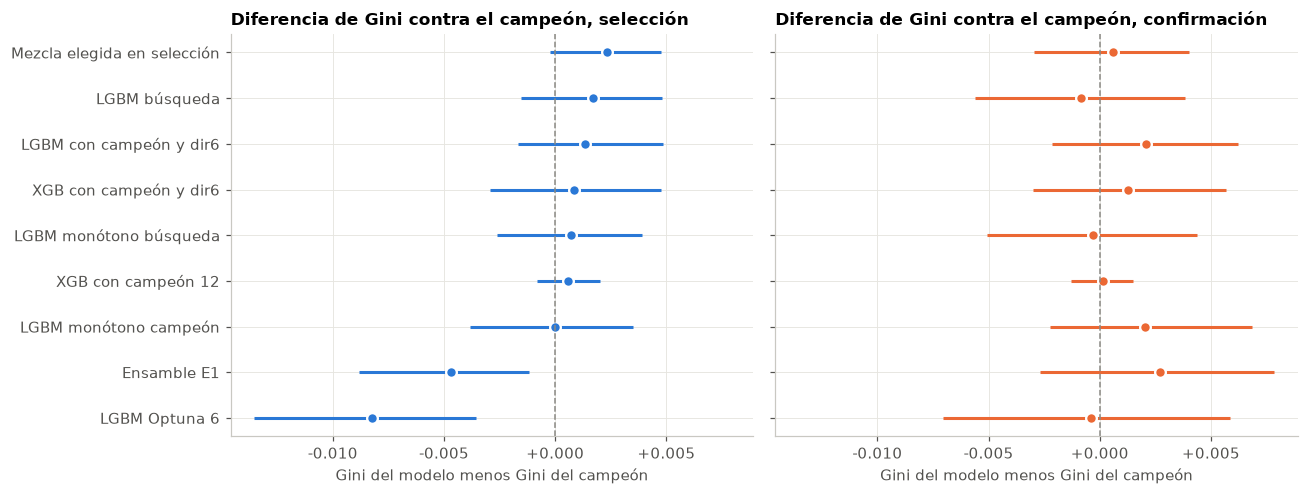

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, sharex=True)
orden = boot[boot.tramo == 'selección'].sort_values('diferencia').modelo.tolist()
for k, (tramo, color) in enumerate([('selección', AZUL), ('confirmación', NARANJA)]):
    b_ = boot[boot.tramo == tramo].set_index('modelo').loc[orden]
    yy = np.arange(len(b_))
    ax[k].hlines(yy, b_.ic95_inferior, b_.ic95_superior, color=color, lw=2)
    ax[k].plot(b_.diferencia, yy, 'o', color=color, ms=7, mec='white', mew=1.5)
    ax[k].axvline(0, color=GRIS, lw=1, ls='--')
    ax[k].set(title=f'Diferencia de Gini contra el campeón, {tramo}', xlabel='Gini del modelo menos Gini del campeón')
ax[0].set_yticks(np.arange(len(orden)), orden)
ax[0].xaxis.set_major_locator(mpl.ticker.MaxNLocator(5)); ax[0].xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:+.3f}'))
fig.tight_layout(); guardar(fig, 'A12_bootstrap_contra_campeon')

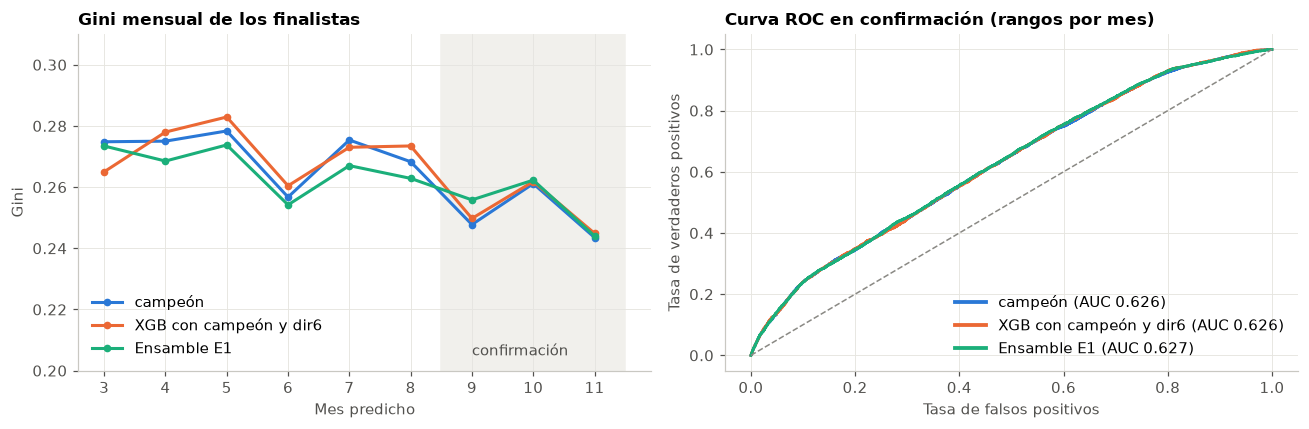

,grupo,modelo,gini_seleccion,gini_confirmacion,std_mensual,gini_minimo,auc_confirmacion,ks_confirmacion,pr_auc_confirmacion,f1_confirmacion,contactar,brier_confirmacion
56,H,Mezcla por rangos elegida en selección,0.2737,0.2514,0.0122,0.2455,0.6257,0.1577,0.2378,0.2834,0.31,NaN
51,G,LGBM búsqueda de 40 configuraciones con campeó...,0.2731,0.2500,0.0121,0.2453,0.6250,0.1586,0.2377,0.2810,0.29,0.1228
38,F,LGBM con campeón y dir6,0.2726,0.2530,0.0115,0.2441,0.6265,0.1584,0.2373,0.2847,0.32,0.1266
53,G,LGBM monótono con parámetros de la búsqueda,0.2722,0.2506,0.0115,0.2451,0.6253,0.1563,0.2376,0.2825,0.31,0.1228
39,F,XGB con campeón y dir6,0.2721,0.2521,0.0120,0.2449,0.6261,0.1580,0.2376,0.2842,0.33,0.1228
48,F,XGB con campeón 12,0.2719,0.2510,0.0128,0.2445,0.6255,0.1570,0.2364,0.2852,0.33,0.1229
0,referencia,"campeón LGBM 12 variables, 5 semillas",0.2714,0.2508,0.0122,0.2435,0.6254,0.1569,0.2363,0.2850,0.34,0.1267
52,G,LGBM monótono con parámetros del campeón,0.2714,0.2530,0.0111,0.2423,0.6265,0.1593,0.2373,0.2839,0.33,0.1266
40,F,CatBoost con campeón y dir6,0.2690,0.2499,0.0128,0.2450,0.6249,0.1571,0.2356,0.2813,0.28,0.1229
49,F,CatBoost con campeón 12,0.2682,0.2481,0.0127,0.2422,0.6240,0.1567,0.2339,0.2814,0.32,0.1230


In [34]:
top = {'campeón': base, 'XGB con campeón y dir6': OOF['XGB con campeón y dir6'], 'Ensamble E1': OOF['Ensamble E1']}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for (n_, o_), color in zip(top.items(), [AZUL, NARANJA, AQUA]):
    ax[0].plot(MESES, [gini(o_[m][0], o_[m][1]) for m in MESES], color=color, marker='o', ms=4, label=n_)
    y_ = np.concatenate([o_[m][0] for m in CONF]); r_ = rango_mes(o_, CONF); f, t, _ = roc_curve(y_, r_)
    ax[1].plot(f, t, color=color, lw=1.8, label=f'{n_} (AUC {roc_auc_score(y_, r_):.3f})')
ax[0].axvspan(8.5, 11.5, color='#f1f0ec', zorder=0); ax[0].text(9, 0.205, 'confirmación', color=TINTA2)
ax[0].set(title='Gini mensual de los finalistas', xlabel='Mes predicho', ylabel='Gini', ylim=(0.2, 0.31), xticks=MESES); ax[0].legend(loc='lower left')
ax[1].plot([0, 1], [0, 1], color=GRIS, lw=1, ls='--')
from matplotlib.lines import Line2D
ax[1].legend(handles=[Line2D([0], [0], color=c_, lw=2.5) for c_ in [AZUL, NARANJA, AQUA]], labels=[l.get_label() for l in ax[1].get_lines()[:3]], loc='lower right')
ax[1].set(title='Curva ROC en confirmación (rangos por mes)', xlabel='Tasa de falsos positivos', ylabel='Tasa de verdaderos positivos')
fig.tight_layout(); guardar(fig, 'A13_finalistas_mensual_y_roc')

completa = pd.DataFrame(RES).drop_duplicates('modelo', keep='last')
completa.to_csv(ART / 'A11_experimentos.csv', index=False)
completa[completa.grupo.isin(['referencia', 'F', 'G', 'H'])][['grupo', 'modelo', 'gini_seleccion', 'gini_confirmacion', 'std_mensual', 'gini_minimo',
    'auc_confirmacion', 'ks_confirmacion', 'pr_auc_confirmacion', 'f1_confirmacion', 'contactar', 'brier_confirmacion']].sort_values('gini_seleccion', ascending=False).round(4)

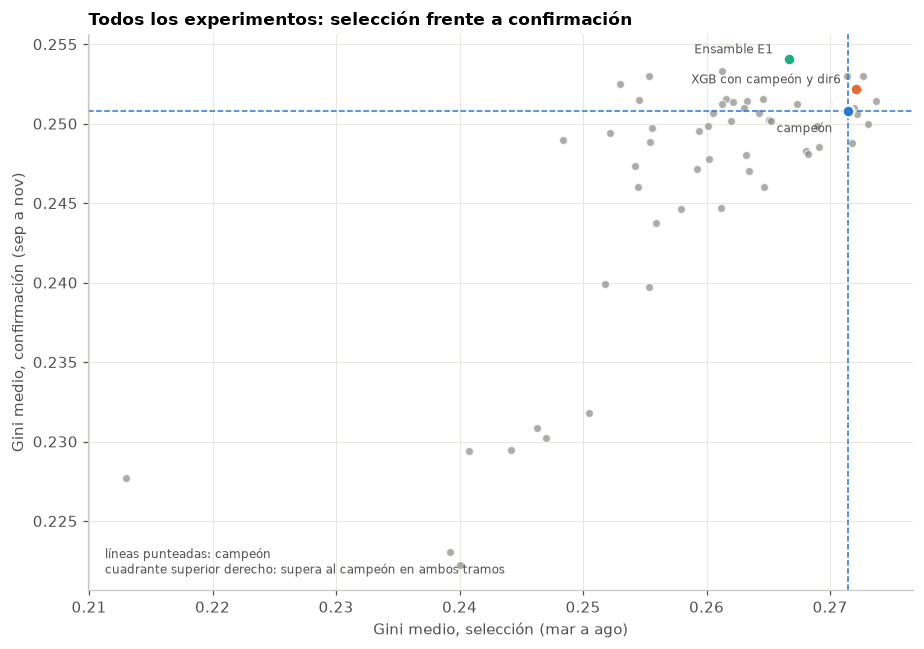

In [35]:
fig, ax = plt.subplots(figsize=(8.5, 6))
cp = pd.DataFrame(RES).drop_duplicates('modelo', keep='last')
ax.scatter(cp.gini_seleccion, cp.gini_confirmacion, s=28, color=GRIS, alpha=0.7, edgecolor='white', linewidth=0.8)
ax.axvline(BASE_REF['sel'], color=AZUL, lw=1, ls='--'); ax.axhline(BASE_REF['conf'], color=AZUL, lw=1, ls='--')
destacar = {'campeón LGBM 12 variables, 5 semillas': (AZUL, (-10, -14), 'campeón'), 'XGB con campeón y dir6': (NARANJA, (-10, 4), 'XGB con campeón y dir6'),
            'Ensamble E1, promedio de rangos de 7 modelos': (AQUA, (-10, 4), 'Ensamble E1')}
for n_, (color, off, txt) in destacar.items():
    r_ = cp.set_index('modelo').loc[n_]
    ax.scatter(r_.gini_seleccion, r_.gini_confirmacion, s=60, color=color, edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(txt, (r_.gini_seleccion, r_.gini_confirmacion), xytext=off, textcoords='offset points', ha='right', color=TINTA2, fontsize=8)
ax.text(0.02, 0.03, 'líneas punteadas: campeón\ncuadrante superior derecho: supera al campeón en ambos tramos', transform=ax.transAxes, color=TINTA2, fontsize=8)
ax.set(title='Todos los experimentos: selección frente a confirmación', xlabel='Gini medio, selección (mar a ago)', ylabel='Gini medio, confirmación (sep a nov)')
fig.tight_layout(); guardar(fig, 'A14_mapa_de_experimentos')

**Lectura de las figuras A12, A13 y A14.** Cuatro candidatos superan al campeón en ambos tramos, y ninguno de forma significativa (todos los intervalos del bootstrap pareado incluyen el cero):

* LGBM con campeón y dir6: más 0,0013 en selección y más 0,0021 en confirmación.
* XGB con campeón y dir6: más 0,0008 y más 0,0013.
* XGB con las 12 variables del campeón: más 0,0006 y más 0,0002.
* Mezcla por rangos elegida en selección: más 0,0023 y más 0,0006. Se eligió entre 168 combinaciones mirando la selección, de modo que su ventaja en ese tramo está sesgada al alza.

Tres patrones confirman que se está optimizando ruido. La búsqueda de LightGBM sube en selección, donde se optimizó (0,2731), y baja en confirmación (0,2500). El ensamble E1, que había parecido el mejor mirando septiembre a noviembre (0,2540), es significativamente peor en selección (0,0047 menos). Y la ventaja del LGBM con campeón y dir6 en selección era nula en una ejecución previa con un cambio mínimo de implementación.

Con solo las tres variables más fuertes (dir3), el Gini cae a 0,247: activo_movil, tiene_tarjeta_credito y ratio_deuda_ingresos aportan cerca de 0,025. Las variables de mes y cohorte no ayudan, porque son constantes dentro de diciembre.

En la figura A13, los finalistas tienen curvas ROC superpuestas y Gini mensuales que suben y bajan juntos: ordenan casi igual a los clientes. En la figura A14, los experimentos forman una nube compacta alrededor del campeón, sin ninguno que se separe del ruido.

## 11. Lectura por segmentos para el negocio

El Gini del reto se calcula sobre toda la población de diciembre, por lo que no se pueden excluir clientes. Sin embargo, el modelo no ordena igual de bien en todos los segmentos, y eso orienta la estrategia comercial. Se usa el Gini de confirmación del campeón dentro de cada segmento.

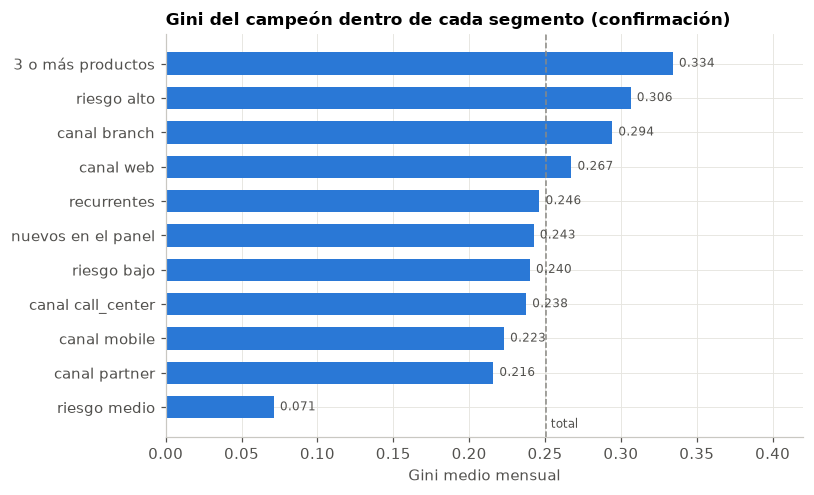

,filas,tasa,gini
riesgo medio,9595.0,0.148,0.071
canal partner,3076.0,0.144,0.216
canal mobile,7977.0,0.151,0.223
canal call_center,4210.0,0.157,0.238
riesgo bajo,13103.0,0.184,0.240
nuevos en el panel,3920.0,0.179,0.243
recurrentes,25880.0,0.145,0.246
canal web,9910.0,0.153,0.267
canal branch,4627.0,0.137,0.294
riesgo alto,7102.0,0.090,0.306


In [36]:
cf = pd.concat([lab[lab.t == m].assign(p=base[m][1]) for m in CONF])
segs = {'riesgo bajo': cf.banda_riesgo == 'low', 'riesgo medio': cf.banda_riesgo == 'medium', 'riesgo alto': cf.banda_riesgo == 'high',
        '3 o más productos': cf.numero_productos >= 3, 'nuevos en el panel': cf.h_k == 0, 'recurrentes': cf.h_k > 0}
for c_ in cf.canal_adquisicion.cat.categories:
    segs[f'canal {c_}'] = cf.canal_adquisicion == c_
seg = pd.DataFrame({k: {'filas': v.sum(), 'tasa': cf.objetivo[v].mean(), 'gini': np.mean([gini(cf[v & (cf.t == m)].objetivo, cf[v & (cf.t == m)].p) for m in CONF])}
                    for k, v in segs.items()}).T.sort_values('gini')
seg.to_csv(ART / 'A15_gini_por_segmento.csv')
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(seg.index, seg.gini, color=AZUL, height=0.65)
ax.axvline(BASE_REF['conf'], color=GRIS, ls='--', lw=1); ax.text(BASE_REF['conf'] + 0.003, -0.6, 'total', color=TINTA2, fontsize=8)
for i, v in enumerate(seg.gini):
    ax.text(v + 0.004, i, f'{v:.3f}', va='center', fontsize=8, color=TINTA2)
ax.set(title='Gini del campeón dentro de cada segmento (confirmación)', xlabel='Gini medio mensual', xlim=(0, 0.42))
fig.tight_layout(); guardar(fig, 'A15_gini_por_segmento')
seg.round(3)

**Lectura de la figura A15.** El modelo ordena muy distinto según el segmento. Ordena bien a los clientes con 3 o más productos (Gini de 0,334), de riesgo alto (0,306) y captados por sucursal (0,294) o web (0,267). En riesgo medio el orden es casi aleatorio (0,071), y en los canales partner (0,216) y móvil (0,223) es más débil.

Recomendación de negocio: usar el modelo para priorizar a clientes con 3 o más productos y de riesgo alto, y no invertir esfuerzo de priorización en riesgo medio. El Gini del reto, sin embargo, se calcula sobre toda la población, y separar segmentos no lo mejora (sección 9).

## 12. Entrenamiento final y archivos de envío

Cada modelo se reentrena con enero a noviembre y puntúa diciembre. Se generan cuatro archivos en la carpeta entrega; el archivo submission.csv del notebook principal no se modifica.

* submission_campeon.csv: campeón con cinco semillas. Su probabilidad se recalibra con Platt ajustado en la confirmación, porque el scale_pos_weight de 0,61 la subestima. Platt es monótono y no cambia el orden.
* submission_xgb_champ_dir6.csv: XGBoost con las variables del campeón y dir6, probabilidad sin calibrar.
* submission_lgbm_optuna_6vars.csv: LightGBM de seis variables ajustado con Optuna, probabilidad sin calibrar.
* submission_ensamble_e1.csv: promedio de rangos de los siete modelos de E1, convertido a probabilidad con Platt ajustado en la confirmación.

Antes de guardar se valida el formato: 9900 filas, columnas id_cliente y prediccion, mismo orden que test.csv, sin nulos y con valores entre 0 y 1.

In [37]:
orden = pd.read_csv(DATOS / 'test.csv', usecols=['id_cliente']).id_cliente
dic = al[al.t == 12].set_index('id_cliente').loc[orden].reset_index()
lab_final = al[al.objetivo.notna()]
assert all((lab_final[c].cat.categories == dic[c].cat.categories).all() for c in CAT)

def platt(out_conf, score_dic):
    lg = lambda s: np.log(np.clip(s, 1e-6, 1 - 1e-6) / (1 - np.clip(s, 1e-6, 1 - 1e-6))).reshape(-1, 1)
    s_ = np.concatenate([out_conf[m][1] for m in CONF]); y_ = np.concatenate([out_conf[m][0] for m in CONF])
    return LogisticRegression(C=1e6).fit(lg(s_), y_).predict_proba(lg(score_dic))[:, 1]

envios = {}
envios['campeon'] = platt(base, lgbm(CHP, semillas=range(42, 47))(lab_final, dic, CHAMP))
envios['xgb_champ_dir6'] = XGBF(lab_final, dic, FCD)
envios['lgbm_optuna_6vars'] = lgbm(P6)(lab_final, dic, SIXN)
r_dic = np.mean([rankdata(aj(lab_final, dic, ff)) / len(dic) for _, aj, ff in MIEMBROS_E1.values()], 0)
envios['ensamble_e1'] = platt(OOF['Ensamble E1'], r_dic)

original = pd.read_csv(ENT / 'submission.csv')
control = []
for k, p in envios.items():
    sub = pd.DataFrame({'id_cliente': dic.id_cliente.values, 'prediccion': p})
    assert len(sub) == 9900 and list(sub.columns) == ['id_cliente', 'prediccion'] and (sub.id_cliente.values == orden.values).all()
    assert sub.prediccion.notna().all() and sub.prediccion.between(0, 1).all()
    sub.to_csv(ENT / f'submission_{k}.csv', index=False)
    control.append(dict(archivo=f'submission_{k}.csv', media=p.mean(), minimo=p.min(), maximo=p.max(),
                        spearman_con_submission_original=pd.Series(p).corr(original.prediccion, method='spearman')))
control = pd.DataFrame(control).set_index('archivo')
control.to_csv(ART / 'A16_control_envios.csv'); control.round(4)

,media,minimo,maximo,spearman_con_submission_original
archivo,,,,
submission_campeon.csv,0.1502,0.0340,0.4854,1.0000
submission_xgb_champ_dir6.csv,0.1406,0.0186,0.4364,0.9678
submission_lgbm_optuna_6vars.csv,0.1413,0.0418,0.3872,0.9361
submission_ensamble_e1.csv,0.1496,0.0212,0.5942,0.9573


**Lectura del control de envíos.** Los cuatro archivos pasan los controles de formato. El campeón regenerado ordena a los clientes exactamente igual que el submission.csv del notebook principal (correlación de Spearman de 1,000), lo que confirma que el modelo se reproduce. Las alternativas ordenan de forma muy parecida (correlación entre 0,936 y 0,968). Las probabilidades medias están entre 14,1 y 15,0 por ciento, cerca de la tasa histórica.

## 13. Conclusiones

1. **No hay una falla en el pipeline.** El techo de 0,25 a 0,27 de Gini lo pone la información disponible.
2. **Por qué el techo es bajo.** Las variables son una foto fija sin fecha. Solo 6 de 21 variables tienen efecto, con reglas simples y efectos moderados. La probabilidad de cada cliente queda fijada por su foto, sin información oculta que el historial revele. Diciembre es la población más agotada del año. El resto es azar mensual.
3. **Por qué la fuga llega a 0,70 o más.** Explota la regla del panel: quien convierte no vuelve a aparecer. No apunta a una variable legítima faltante y no sirve en diciembre.
4. **El ruido de medición manda.** El error estándar del Gini (0,009) es mayor que cualquier mejora encontrada. Elegir entre muchas alternativas por diferencias de 0,002 es elegir por azar, como mostraron la búsqueda de hiperparámetros, la mezcla por rangos y el ensamble E1.
5. **Validación.** La ventana móvil mensual es el único esquema que reproduce la situación de diciembre. Los esquemas aleatorios por fila o por cliente engañan con modelos flexibles.
6. **Envío.** Ningún modelo supera al campeón de forma significativa. Por simplicidad y robustez, el envío principal es submission_campeon.csv, que ordena igual que el submission.csv original. Como segundo envío, si el reto lo permite, submission_xgb_champ_dir6.csv, que supera al campeón en ambos tramos aunque sin significancia. El LGBM con campeón y dir6 obtuvo en esta ejecución una ventaja algo mayor, pero su orden frente al XGB cambia con detalles de implementación, otra señal de que las diferencias son ruido.
7. **Valor de negocio.** Concentrar la priorización en clientes con 3 o más productos, de riesgo alto y captados por sucursal o web, donde el modelo ordena con un Gini de 0,27 a 0,33.